# Final runs: results

Everything logged by the final runs, each at the same compute $C \approx 8.48\times10^{17}$ FLOPs.
Reads only `results/` (committed), so it runs anywhere after `git pull`. Refresh `results/` on the cluster first:
`uv run --frozen python analysis/collect_results.py`, then commit and push.

Conditions, drawn the same way in every plot:
**blue = SP, orange = CompleteP; dashed = LR transferred from 512x16, solid = LR tuned per shape.**
A run that serves two conditions (e.g. `sp-512x16` is (a) and (b)) is drawn in both.
Missing conditions (not run yet, e.g. CompleteP-tuned) are listed by the setup cell and left out of the plots;
rerun the notebook when they are in.

1. Overview
2. Final validation loss (the main comparison)
3. Loss curves (against FLOPs and against wall-clock)
4. Throughput: MFU, tokens/s, training and wall-clock time, memory
5. Optimization: gradient norm, clipping, loss spikes, LR schedule
6. Per-layer diagnostics (`diag.csv`): gradient RMS, Adam update size, weights, $\epsilon$ / starvation
7. Appendix: coordinate check

The LR sweeps themselves are in `tuning.ipynb`.

In [1]:
import functools
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RESULTS = Path("../results") if Path("../results").exists() else Path("results")  # from analysis/ or the repo root
SHAPES = ["256x64", "384x28", "512x16", "640x10", "1024x4"]  # deep -> wide
D = {s: int(s.split("x")[0]) for s in SHAPES}
L = {s: int(s.split("x")[1]) for s in SHAPES}
V, T = 50304, 2048


def c_tok(d, l):
    """Training FLOPs per token."""
    return 6 * 12 * d * d * l + 6 * d * V + 6 * l * T * d



BLUE, ORANGE = "#2a78d6", "#eb6834"
COND = {"a": "SP-transfer", "b": "SP-tuned", "c": "CompleteP-transfer", "d": "CompleteP-tuned"}
STYLE = {"a": dict(color=BLUE, linestyle="--", marker="o"), "b": dict(color=BLUE, linestyle="-", marker="s"),
         "c": dict(color=ORANGE, linestyle="--", marker="o"), "d": dict(color=ORANGE, linestyle="-", marker="s")}
SHAPE_COLORS = dict(zip(SHAPES, plt.cm.viridis(np.linspace(0.0, 0.85, len(SHAPES)))))  # ordinal: deep -> wide
plt.rcParams.update({"axes.grid": True, "grid.color": "0.9", "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110, "legend.frameon": False})

runs = pd.read_csv(RESULTS / "runs.csv")
final = runs[runs["kind"] == "final"].copy()
final["gpu"] = [json.loads((RESULTS / "runs" / n / "config.json").read_text()).get("gpu_name", "?") for n in final["name"]]
FINAL = final.set_index("name")
# one row per (condition, run): a run with condition "a+b" serves both
by_cond = final.assign(condition=final["condition"].fillna("").astype(str).str.split("+")).explode("condition")
by_cond = by_cond[by_cond["condition"].isin(list(COND))]


@functools.cache
def load(name, file):
    path = RESULTS / "runs" / name / file
    return pd.read_csv(path) if path.exists() else None


def run_of(cond, shape):
    """The finished final run of a condition at a shape, or None."""
    r = by_cond[(by_cond["condition"] == cond) & (by_cond["shape"] == shape) & (by_cond["status"] == "finished")]
    return r.iloc[0] if len(r) else None


def curve(name, file="eval.csv"):
    """A run's log with FLOPs so far and fraction of training added."""
    df = load(name, file).copy()
    r = FINAL.loc[name]
    df["flops"] = df["tokens"] * c_tok(r["d"], r["L"])
    df["frac"] = df["iter"] / r["max_iters"]
    return df


X = {s: i for i, s in enumerate(SHAPES)}


def shape_axis(ax):
    """Shapes as categories, deep -> wide."""
    ax.set_xticks(range(len(SHAPES)), [f"{s}\nd/L={round(D[s] / L[s])}" for s in SHAPES])
    ax.set_xlim(-0.5, len(SHAPES) - 0.5)


def shape_legend(fig, axes, title="shape (deep -> wide)"):
    """One legend for the whole figure with every shape drawn in it (some panels miss shapes)."""
    handles = {l: h for ax in np.ravel(axes) for h, l in zip(*ax.get_legend_handles_labels())}
    shapes = [s for s in SHAPES if s in handles]
    extra = [l for l in handles if l not in SHAPES]
    fig.legend([handles[l] for l in shapes + extra], shapes + extra, loc="outside upper center",
               ncol=len(shapes) + len(extra), title=title)


def where(row):
    """'mlp.c_proj, layer 2' / 'wte' for a diag.csv row."""
    return row["kind"] if pd.isna(row["layer"]) else f"{row['kind']}, layer {int(row['layer'])}"


missing = [f"{COND[c]} {s}" for c in COND for s in SHAPES if run_of(c, s) is None]
print(f"{len(final)} final runs, {(final['status'] == 'finished').sum()} finished, GPUs: {sorted(set(final['gpu']))}")
print("missing (condition, shape):", ", ".join(missing) or "none")

15 final runs, 15 finished, GPUs: ['NVIDIA H100 NVL']
missing (condition, shape): none


## 1. Overview

One row per run. `condition` lists every condition the run serves. Times are from `eval.csv` / `train.csv`
(`train_time_h` = training steps only, `wall_time_h` = everything incl. evals and checkpoints, summed over resumes).
All final runs should be on the same GPU type, otherwise times and MFU are not comparable.

In [2]:
cols = ["name", "condition", "shape", "lr", "max_iters", "status", "final_val_loss",
        "train_time_h", "wall_time_h", "tok_per_s", "mfu", "gpu"]
final.sort_values(["parameterization", "L"], ascending=[False, False])[cols].reset_index(drop=True)

,name,condition,shape,lr,max_iters,status,final_val_loss,train_time_h,wall_time_h,tok_per_s,mfu,gpu
0,sp-transfer-256x64,a,256x64,0.001200,5571,finished,3.591458,1.609,1.694,252055.0,17.53,NVIDIA H100 NVL
1,sp-tuned-256x64,b,256x64,0.000600,5571,finished,3.733656,1.607,1.692,252423.0,17.55,NVIDIA H100 NVL
2,sp-transfer-384x28,a,384x28,0.001200,5932,finished,3.428069,1.295,1.358,333502.0,21.78,NVIDIA H100 NVL
3,sp-tuned-384x28,b,384x28,0.000600,5932,finished,3.526675,1.294,1.356,333860.0,21.80,NVIDIA H100 NVL
4,sp-512x16,a+b,512x16,0.001200,5805,finished,3.379615,1.053,1.110,401342.0,26.78,NVIDIA H100 NVL
5,sp-transfer-640x10,a+b,640x10,0.001200,5707,finished,3.373222,0.981,1.030,423566.0,28.75,NVIDIA H100 NVL
6,sp-transfer-1024x4,a+b,1024x4,0.001200,4890,finished,3.444241,0.765,0.809,465317.0,36.86,NVIDIA H100 NVL
7,completep-256x64,c+d,256x64,0.007812,5571,finished,3.517900,1.600,1.684,253561.0,17.63,NVIDIA H100 NVL
8,completep-384x28,c,384x28,0.007812,5932,finished,3.438822,1.289,1.353,335002.0,21.88,NVIDIA H100 NVL
9,completep-tuned-384x28,d,384x28,0.003906,5932,finished,3.422561,1.307,1.371,330578.0,21.59,NVIDIA H100 NVL


## 2. Final validation loss

The main result: val loss after the last step (same 1,600 fixed SlimPajama validation windows for every run).
Reading: a U-curve in the dashed lines that flattens
in the solid ones points to LR detuning, not depth.

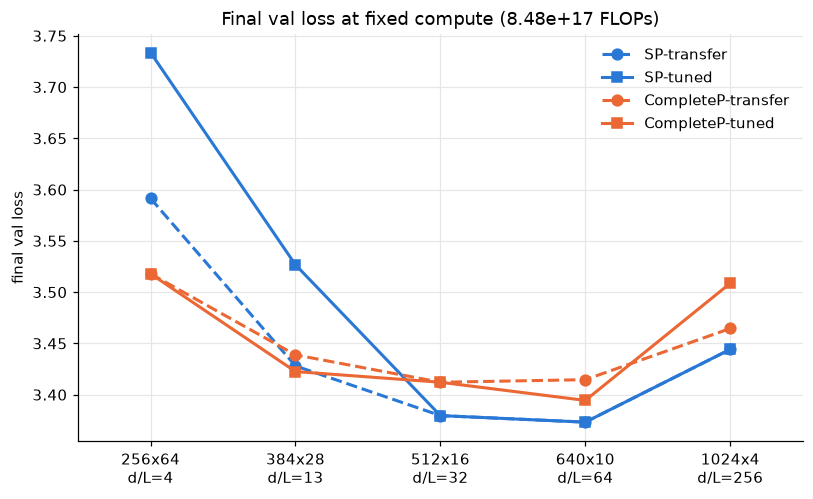

condition,SP-transfer,SP-tuned,CompleteP-transfer,CompleteP-tuned,best condition
shape,,,,,
256x64,3.5915,3.7337,3.5179,3.5179,CompleteP-transfer
384x28,3.4281,3.5267,3.4388,3.4226,CompleteP-tuned
512x16,3.3796,3.3796,3.4121,3.4121,SP-transfer
640x10,3.3732,3.3732,3.4146,3.3944,SP-transfer
1024x4,3.4442,3.4442,3.4646,3.5087,SP-transfer


In [3]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
for c in COND:
    pts = [(X[s], run_of(c, s)["final_val_loss"]) for s in SHAPES if run_of(c, s) is not None]
    if pts:
        ax.plot(*zip(*pts), **STYLE[c], linewidth=2, markersize=7, label=COND[c])
shape_axis(ax)
ax.set_ylabel("final val loss")
ax.set_title(f"Final val loss at fixed compute ({c_tok(512, 16) * 20 * (12 * 512**2 * 16 + 512 * V):.2e} FLOPs)")
ax.legend(loc="upper right")
plt.show()

pivot = by_cond.pivot_table(index="shape", columns="condition", values="final_val_loss").reindex(SHAPES)
pivot = pivot.rename(columns=COND)
pivot["best condition"] = pivot.idxmin(axis=1)
pivot.round(4)

In [4]:
(3.4442 - 3.3796)-	(3.4646 - 3.4121) / (2 * 0.0076)

-3.3893473684210376

In [5]:
(0.06459999999999999 - 0.05249999999999977)

0.012100000000000222

In [6]:
(0.06459999999999999 - 0.05249999999999977) / (2 * 0.0076)



0.796052631578962

**Gaps** (loss of the first minus the second; positive = the second is better). The four readings of the 2x2 design.

In [7]:
def gap(x, y):
    return pd.Series({s: run_of(x, s)["final_val_loss"] - run_of(y, s)["final_val_loss"]
                      if run_of(x, s) is not None and run_of(y, s) is not None else np.nan for s in SHAPES})


pd.DataFrame({
    "(a)-(b) SP: cost of transferring the LR": gap("a", "b"),
    "(c)-(d) CompleteP: cost of transferring": gap("c", "d"),
    "(a)-(c) parameterization, both transferred": gap("a", "c"),
    "(b)-(d) parameterization, both tuned": gap("b", "d"),
}).round(4)

,(a)-(b) SP: cost of transferring the LR,(c)-(d) CompleteP: cost of transferring,"(a)-(c) parameterization, both transferred","(b)-(d) parameterization, both tuned"
256x64,-0.1422,0.0000,0.0736,0.2158
384x28,-0.0986,0.0163,-0.0108,0.1041
512x16,0.0000,0.0000,-0.0325,-0.0325
640x10,0.0000,0.0202,-0.0414,-0.0212
1024x4,0.0000,-0.0441,-0.0203,-0.0644


**Best shape per condition** and how much depth/width allocation matters: `spread` = worst minus best shape,
`deepest - best` = penalty of 256x64, `widest - best` = penalty of 1024x4.

In [8]:
rows = {}
for c in COND:
    losses = pd.Series({s: run_of(c, s)["final_val_loss"] for s in SHAPES if run_of(c, s) is not None})
    if losses.empty:
        continue
    rows[COND[c]] = {"shapes done": len(losses), "best shape": losses.idxmin(), "best loss": losses.min(),
                     "spread": losses.max() - losses.min(),
                     "deepest - best": losses.get("256x64", np.nan) - losses.min(),
                     "widest - best": losses.get("1024x4", np.nan) - losses.min()}
pd.DataFrame(rows).T.round(4)

,shapes done,best shape,best loss,spread,deepest - best,widest - best
SP-transfer,5,640x10,3.373222,0.218236,0.218236,0.071019
SP-tuned,5,640x10,3.373222,0.360434,0.360434,0.071019
CompleteP-transfer,5,512x16,3.412145,0.105755,0.105755,0.052415
CompleteP-tuned,5,640x10,3.394411,0.123489,0.123489,0.114256


### Does the 10% tuning horizon pick the right LR?

Wherever a shape has final runs at two or more LRs (e.g. SP-transfer and SP-tuned at 256x64), compare the ranking
of those LRs in the tuning run (10% of the tokens) with their ranking at full length. If they disagree, the tuned
LR is not the best LR for the full run (the optimal LR shifts with training length),
and "tuned" is not an upper bound there.

In [9]:
tune = runs[runs["kind"] == "tune"]
rows = []
done = final[final["status"] == "finished"]
for (p, s), g in done.groupby(["parameterization", "shape"]):
    if g["lr"].nunique() < 2:
        continue
    for _, r in g.sort_values("lr").iterrows():
        t = tune[(tune["parameterization"] == p) & (tune["shape"] == s) & np.isclose(tune["lr"], r["lr"])]
        rows.append({"parameterization": p, "shape": s, "lr": r["lr"], "run": r["name"],
                     "tuning val loss (10%)": t["final_val_loss"].iloc[0] if len(t) else np.nan,
                     "final val loss": r["final_val_loss"]})
horizon = pd.DataFrame(rows)
if len(horizon):
    for (p, s), g in horizon.groupby(["parameterization", "shape"]):
        best_tune, best_final = g.loc[g["tuning val loss (10%)"].idxmin(), "lr"], g.loc[g["final val loss"].idxmin(), "lr"]
        print(f"{p} {s}: best LR at 10% = {best_tune:g}, at full length = {best_final:g}"
              + ("" if best_tune == best_final else "   <-- the tuning horizon picked the wrong LR"))
horizon

completep 1024x4: best LR at 10% = 0.00195312, at full length = 0.0078125   <-- the tuning horizon picked the wrong LR
completep 384x28: best LR at 10% = 0.00390625, at full length = 0.00390625
completep 640x10: best LR at 10% = 0.00390625, at full length = 0.00390625
sp 256x64: best LR at 10% = 0.0006, at full length = 0.0012   <-- the tuning horizon picked the wrong LR
sp 384x28: best LR at 10% = 0.0006, at full length = 0.0012   <-- the tuning horizon picked the wrong LR


,parameterization,shape,lr,run,tuning val loss (10%),final val loss
0,completep,1024x4,0.001953,completep-tuned-1024x4,5.492287,3.508667
1,completep,1024x4,0.007812,completep-1024x4,5.676092,3.464561
2,completep,384x28,0.003906,completep-tuned-384x28,5.430182,3.422561
3,completep,384x28,0.007812,completep-384x28,5.458433,3.438822
4,completep,640x10,0.003906,completep-tuned-640x10,5.395936,3.394411
5,completep,640x10,0.007812,completep-640x10,5.616828,3.414644
6,sp,256x64,0.000600,sp-tuned-256x64,6.060480,3.733656
7,sp,256x64,0.001200,sp-transfer-256x64,6.188324,3.591458
8,sp,384x28,0.000600,sp-tuned-384x28,5.709008,3.526675
9,sp,384x28,0.001200,sp-transfer-384x28,5.832502,3.428069


### Seed-to-seed noise (512x16)

Seeds 1-2 of `sp-512x16` and `completep-512x16`, same LR as seed 0, which is the final run.
The seed only changes the init; data order and eval windows are fixed, so this is a lower bound on run-to-run noise.
`SEED_SD` (pooled over SP and CompleteP) is the yardstick for the single-seed gaps below: two single runs differ by
noise alone with SD $\sqrt{2}\,$`SEED_SD`.

pooled seed SD = 0.0076; SD of a difference between two single runs = 0.0107
512x16, mean over seeds: CompleteP - SP = 0.0252 +- 0.0062 (SE), 4.1 SE


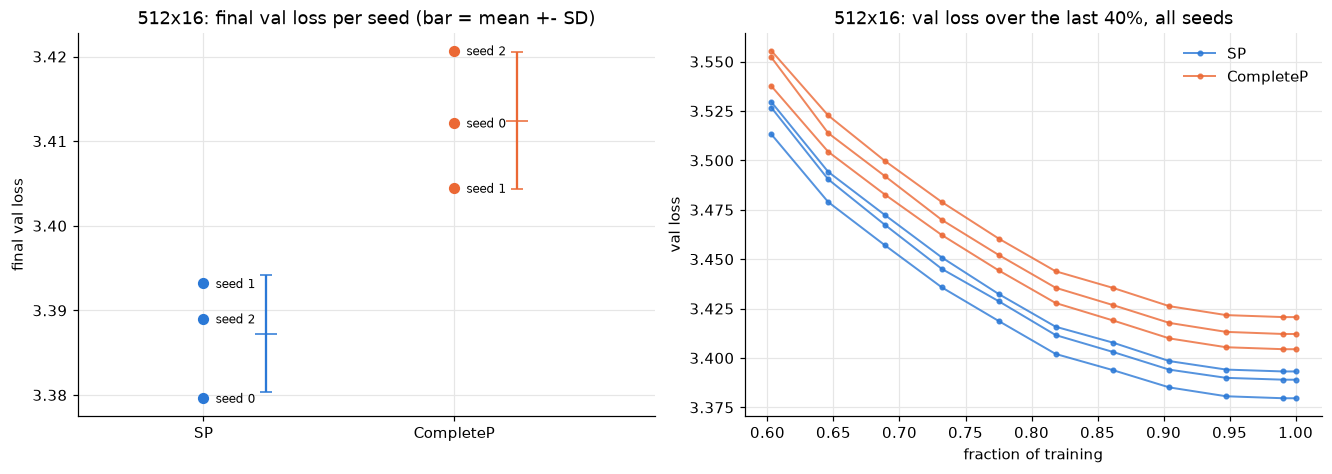

,count,mean,std,min,max,range
parameterization,,,,,,
completep,3,3.4124,0.0081,3.4044,3.4207,0.0163
sp,3,3.3873,0.0069,3.3796,3.3932,0.0136


In [10]:
RUNS = runs.set_index("name")
seed0 = [run_of("a", "512x16")["name"], run_of("c", "512x16")["name"]]
seeds = runs[(runs["status"] == "finished") & ((runs["kind"] == "seed") | runs["name"].isin(seed0))]
assert seeds.groupby("parameterization")["lr"].nunique().eq(1).all(), "seeds of one parameterization must share the LR"

seed_stats = seeds.groupby("parameterization")["final_val_loss"].agg(["count", "mean", "std", "min", "max"])
seed_stats["range"] = seed_stats["max"] - seed_stats["min"]
SEED_SD = np.sqrt((seed_stats["std"] ** 2).mean())  # pooled (equal counts)
m, se = seed_stats["mean"], np.sqrt((seed_stats["std"] ** 2 / seed_stats["count"]).sum())
print(f"pooled seed SD = {SEED_SD:.4f}; SD of a difference between two single runs = {np.sqrt(2) * SEED_SD:.4f}")
print(f"512x16, mean over seeds: CompleteP - SP = {m['completep'] - m['sp']:.4f} +- {se:.4f} (SE), "
      f"{(m['completep'] - m['sp']) / se:.1f} SE")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
for i, (p, color) in enumerate([("sp", BLUE), ("completep", ORANGE)]):
    g = seeds[seeds["parameterization"] == p]
    axes[0].scatter(np.full(len(g), i), g["final_val_loss"], color=color, s=40, zorder=3)
    for _, r in g.iterrows():
        axes[0].annotate(f"seed {r['seed']}", (i, r["final_val_loss"]), xytext=(8, -3), textcoords="offset points", fontsize=8)
        e = load(r["name"], "eval.csv")
        e = e[e["iter"] >= 0.6 * r["max_iters"]]
        axes[1].plot(e["iter"] / r["max_iters"], e["val_loss"], color=color, marker="o", markersize=3, linewidth=1.3,
                     alpha=0.8, label=f"{'SP' if p == 'sp' else 'CompleteP'}" if r["seed"] == 0 else None)
    axes[0].errorbar(i + 0.25, m[p], yerr=seed_stats.loc[p, "std"], color=color, marker="_", markersize=14, capsize=4)
axes[0].set_xticks([0, 1], ["SP", "CompleteP"])
axes[0].set_xlim(-0.5, 1.8)
axes[0].set_ylabel("final val loss")
axes[0].set_title("512x16: final val loss per seed (bar = mean +- SD)")
axes[1].set_xlabel("fraction of training")
axes[1].set_ylabel("val loss")
axes[1].set_title("512x16: val loss over the last 40%, all seeds")
axes[1].legend()
plt.show()

seed_stats.round(4)

**Single-seed gaps against the noise.** Every shape vs 512x16 within a condition, and SP vs CompleteP at each shape
(transferred LRs, seed 0). `z` = gap / ($\sqrt{2}\,$`SEED_SD`); $|z| < 2$ is within seed noise. The noise was measured at
512x16 only and is assumed the same at other shapes.

In [11]:
sd_diff = np.sqrt(2) * SEED_SD
rows = {}
for s in SHAPES:
    la, lc = run_of("a", s)["final_val_loss"], run_of("c", s)["final_val_loss"]
    rows[s] = {"SP-transfer - 512x16": la - run_of("a", "512x16")["final_val_loss"],
               "CompleteP - 512x16": lc - run_of("c", "512x16")["final_val_loss"],
               "SP-transfer - CompleteP": la - lc}
gaps = pd.DataFrame(rows).T
table = pd.concat({"gap": gaps, "z": gaps / sd_diff}, axis=1)
table.style.format("{:.3f}").map(lambda v: "color: #999" if abs(v) < 2 else "", subset=["z"])

### SP 256x64: loss still falling at the highest LR

Every full-length SP 256x64 run: SP-tuned (6e-4, the 10% sweep's pick), SP-transfer (1.2e-3, the 512x16 LR) and the
post-hoc check `check-sp-256x64-lr2.4e-3`. Error bars: $\pm$`SEED_SD` (measured at 512x16).
Left: full length, with CompleteP 256x64 for reference. Right: the same shape in the 10% tuning sweep, where the
ranking is the opposite (optimum at 6e-4). At full length the loss is still decreasing at 2.4e-3, so SP's optimum
for this shape is not bracketed: the SP losses here are upper bounds on what SP can reach at 256x64.

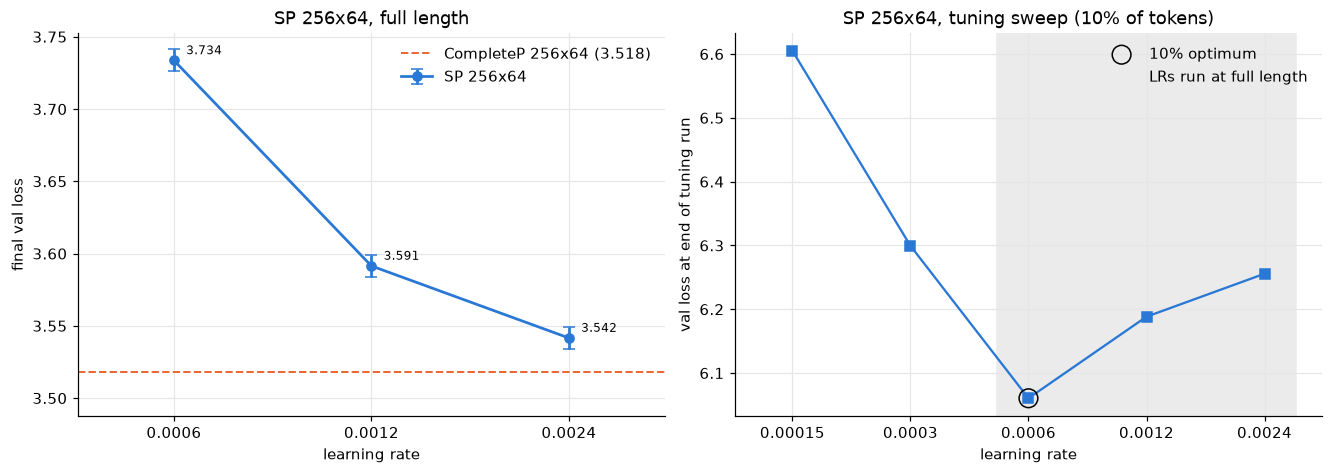

,name,lr,final_val_loss,improvement vs previous LR,in seed SDs of a difference
18,sp-tuned-256x64,0.0006,3.7337,NaN,NaN
15,sp-transfer-256x64,0.0012,3.5915,0.1422,13.2948
0,check-sp-256x64-lr2.4e-3,0.0024,3.5416,0.0499,4.6613


In [12]:
sp256 = runs[(runs["parameterization"] == "sp") & (runs["shape"] == "256x64") & runs["kind"].isin(["final", "check"])
             & (runs["status"] == "finished")].sort_values("lr")
tune256 = runs[(runs["kind"] == "tune") & (runs["parameterization"] == "sp") & (runs["shape"] == "256x64")].sort_values("lr")
cp256 = run_of("c", "256x64")["final_val_loss"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
ax = axes[0]
ax.errorbar(sp256["lr"], sp256["final_val_loss"], yerr=SEED_SD, color=BLUE, marker="o", capsize=4, linewidth=1.8, label="SP 256x64")
for _, r in sp256.iterrows():
    ax.annotate(f"{r['final_val_loss']:.3f}", (r["lr"], r["final_val_loss"]), xytext=(8, 4),
                textcoords="offset points", fontsize=8)
ax.axhline(cp256, color=ORANGE, linestyle="--", linewidth=1.3, label=f"CompleteP 256x64 ({cp256:.3f})")
ax.set_title("SP 256x64, full length")
ax.set_ylabel("final val loss")
ax.set_ylim(cp256 - 0.03, None)
ax.legend(loc="upper right")
ax = axes[1]
ax.plot(tune256["lr"], tune256["final_val_loss"], color=BLUE, marker="s", linewidth=1.5)
best = tune256.loc[tune256["final_val_loss"].idxmin()]
ax.scatter(best["lr"], best["final_val_loss"], s=150, facecolors="none", edgecolors="black", zorder=4, label="10% optimum")
ax.axvspan(sp256["lr"].min() / 1.2, sp256["lr"].max() * 1.2, color="0.92", zorder=0, label="LRs run at full length")
ax.set_title("SP 256x64, tuning sweep (10% of tokens)")
ax.set_ylabel("val loss at end of tuning run")
ax.legend(loc="upper right")
for ax, lrs in zip(axes, [sp256["lr"], tune256["lr"]]):
    ax.set_xscale("log", base=2)
    ax.set_xticks(lrs, [f"{lr:g}" for lr in lrs])
    ax.minorticks_off()
    ax.set_xlim(lrs.min() / 1.4, lrs.max() * 1.4)
    ax.set_xlabel("learning rate")
plt.show()

steps = sp256.assign(**{"improvement vs previous LR": -sp256["final_val_loss"].diff()})
steps["in seed SDs of a difference"] = steps["improvement vs previous LR"] / sd_diff
steps[["name", "lr", "final_val_loss", "improvement vs previous LR", "in seed SDs of a difference"]].round(4)

### Main figure

Left: final val loss against shape for the four conditions (same as the plot at the top of this section). Error bars
are $\pm$`SEED_SD`, the seed noise measured at 512x16; the conditions are shifted slightly left and right of each
shape so their bars don't overlap. Right: the warmup check at SP 256x64. Each setting is drawn relative to its own
loss at 6e-4 (below 0 = better than 6e-4); a circle marks the best LR of each setting. Tuning runs (10% of the
tokens) with the default 10% warmup rank the LRs the opposite way to the full-length runs. With 50% warmup they
match the full-length ranking.
Saved to `results/plots/main_figure.{pdf,png}`.

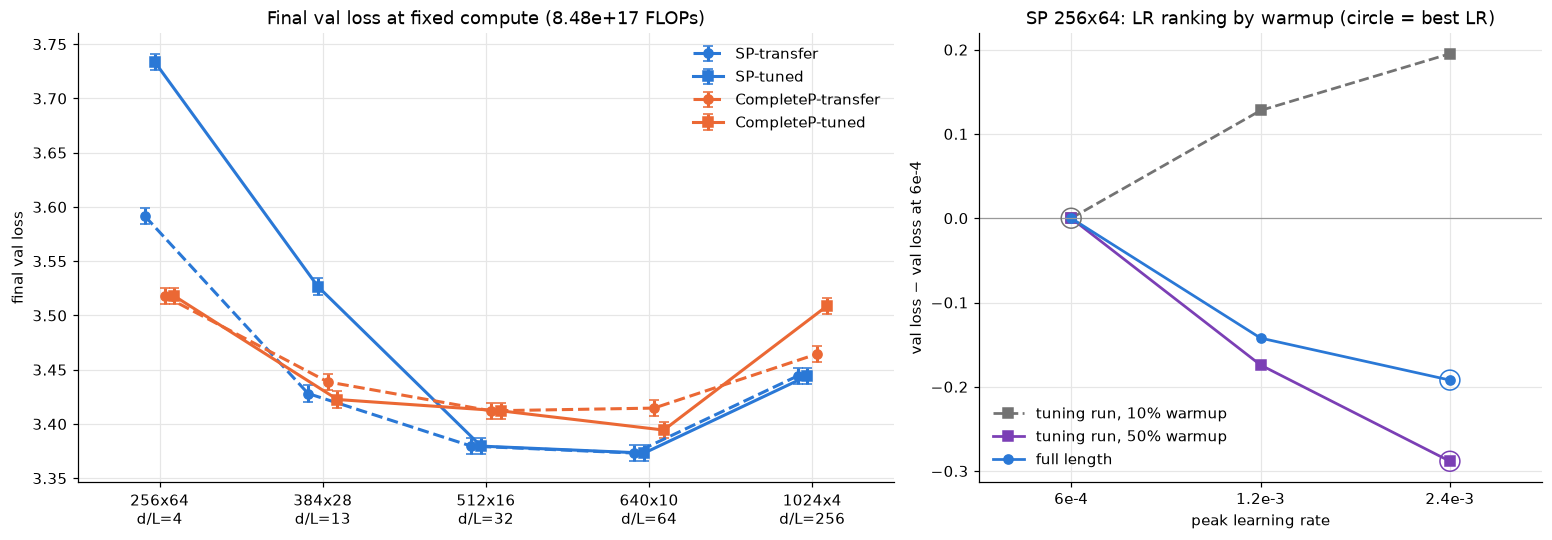

,"tuning run, 10% warmup","tuning run, 50% warmup",full length
lr,,,
0.0006,6.060,5.888,3.734
0.0012,6.188,5.714,3.591
0.0024,6.256,5.600,3.542


In [13]:
# right panel data: SP 256x64 at the LRs of the warmup check
w = runs[(runs["parameterization"] == "sp") & (runs["shape"] == "256x64") & (runs["status"] == "finished")]
W_LRS = sorted(w.loc[w["kind"] == "warmup", "lr"])
W_GROUPS = {"tuning run, 10% warmup": w[w["kind"] == "tune"],
            "tuning run, 50% warmup": w[w["kind"] == "warmup"],
            "full length": w[w["kind"].isin(["final", "check"])]}
W_STYLE = {"tuning run, 10% warmup": dict(color="0.45", linestyle="--", marker="s"),
           "tuning run, 50% warmup": dict(color="#7b3fb5", linestyle="-", marker="s"),
           "full length": dict(color=BLUE, linestyle="-", marker="o")}
lr_str = lambda lr: f"{lr:.1e}".replace(".0e", "e").replace("e-0", "e-")  # 0.0006 -> 6e-4
w_table = pd.DataFrame({g: df.set_index("lr").loc[W_LRS, "final_val_loss"] for g, df in W_GROUPS.items()})

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), constrained_layout=True, gridspec_kw={"width_ratios": [1.45, 1]})
ax = axes[0]
OFFSET = dict(zip(COND, [-0.09, -0.03, 0.03, 0.09]))
for c in COND:
    pts = [(X[s] + OFFSET[c], run_of(c, s)["final_val_loss"]) for s in SHAPES if run_of(c, s) is not None]
    if pts:
        x, y = zip(*pts)
        ax.errorbar(x, y, yerr=SEED_SD, capsize=3, linewidth=2, markersize=6, label=COND[c], **STYLE[c])
shape_axis(ax)
ax.set_ylabel("final val loss")
ax.set_title(f"Final val loss at fixed compute ({c_tok(512, 16) * 20 * (12 * 512**2 * 16 + 512 * V):.2e} FLOPs)")
ax.legend(loc="upper right")

ax = axes[1]
for g in w_table:
    rel = w_table[g] - w_table.loc[min(W_LRS), g]
    ax.plot(W_LRS, rel, label=g, linewidth=1.8, **W_STYLE[g])
    ax.scatter(rel.idxmin(), rel.min(), s=170, facecolors="none", edgecolors=W_STYLE[g]["color"], zorder=4)
ax.axhline(0, color="0.6", linewidth=0.8)
ax.set_xscale("log", base=2)
ax.set_xticks(W_LRS, [lr_str(lr) for lr in W_LRS])
ax.minorticks_off()
ax.set_xlim(min(W_LRS) / 1.4, max(W_LRS) * 1.4)
ax.set_xlabel("peak learning rate")
ax.set_ylabel(f"val loss − val loss at {lr_str(min(W_LRS))}")
ax.set_title("SP 256x64: LR ranking by warmup (circle = best LR)")
ax.legend(loc="lower left")

(RESULTS / "plots").mkdir(exist_ok=True)
for ext in ["pdf", "png"]:
    fig.savefig(RESULTS / "plots" / f"main_figure.{ext}", dpi=200, bbox_inches="tight")
plt.show()

w_table.round(3)

## 3. Loss curves

Val loss at every eval (every 250 steps, plus the last step), against training FLOPs so far
(tokens x $C_{tok}$ of the shape), so all runs end at the same x. Top row: whole run. Bottom row: last 40%.

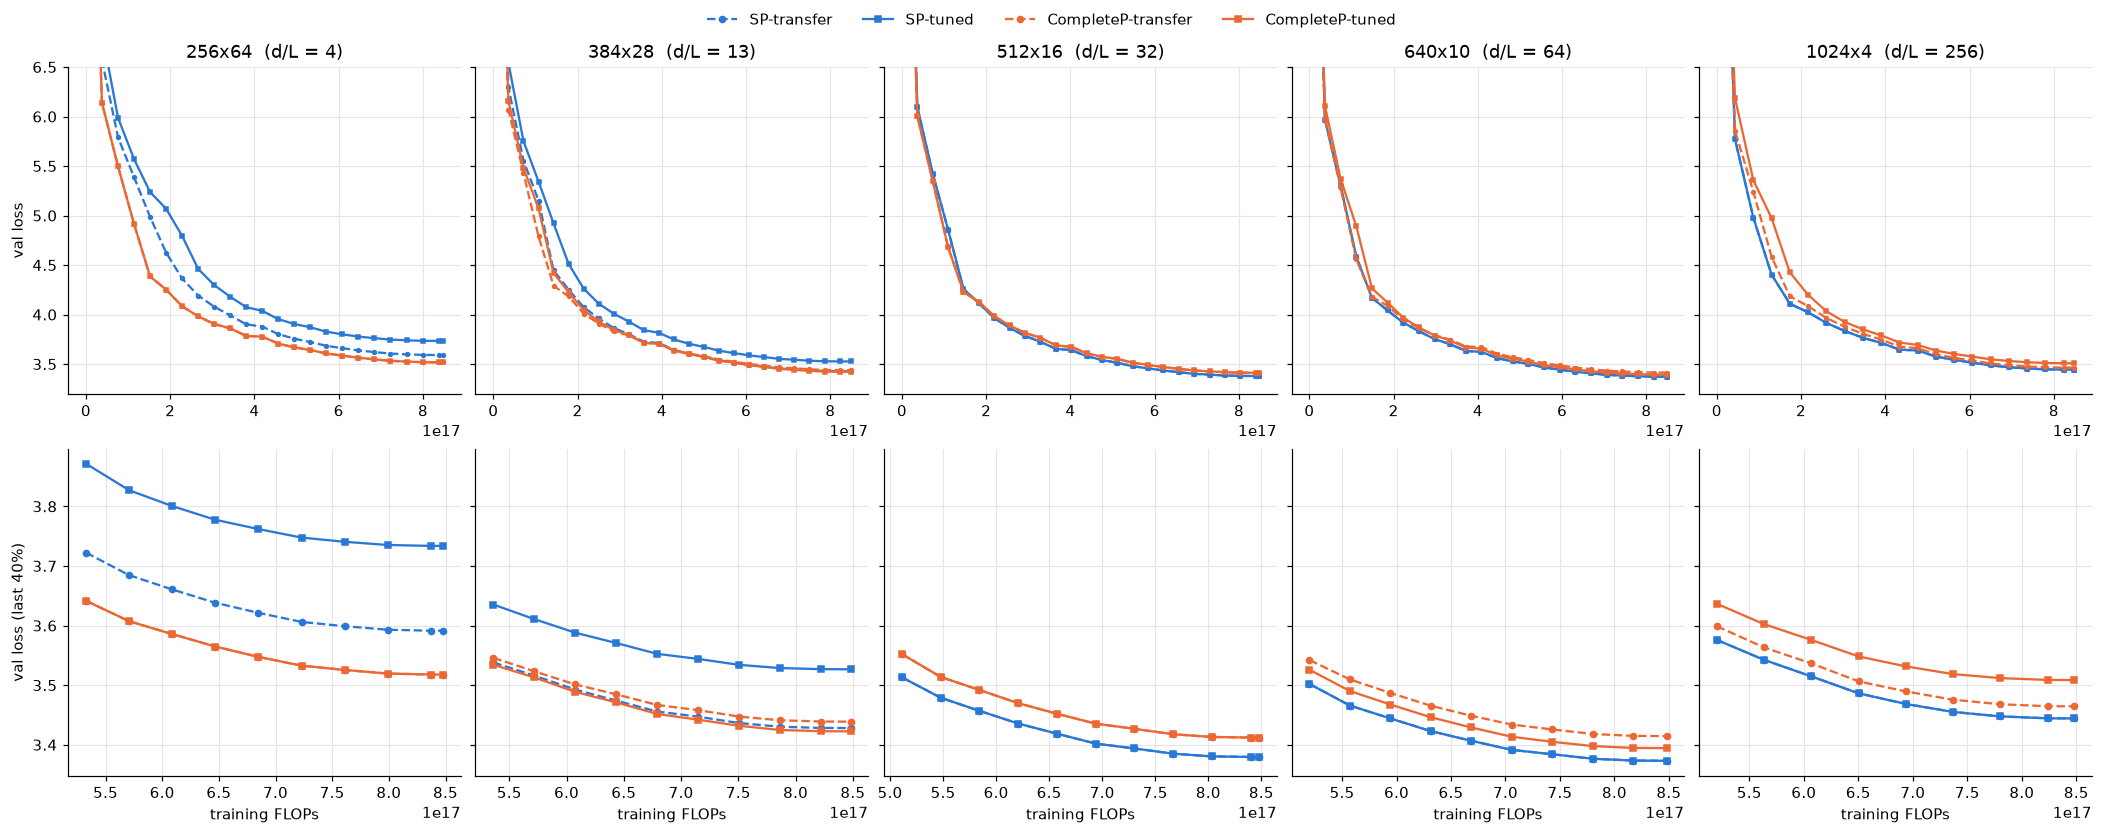

In [14]:
fig, axes = plt.subplots(2, len(SHAPES), figsize=(19, 7.5), sharey="row", constrained_layout=True)
for j, s in enumerate(SHAPES):
    for c in COND:
        r = run_of(c, s)
        if r is None:
            continue
        e = curve(r["name"])
        axes[0, j].plot(e["flops"], e["val_loss"], **STYLE[c], markersize=2.5, linewidth=1.5, label=COND[c])
        z = e[e["frac"] >= 0.6]
        axes[1, j].plot(z["flops"], z["val_loss"], **STYLE[c], markersize=4, linewidth=1.5, label=COND[c])
    axes[0, j].set_title(f"{s}  (d/L = {round(D[s] / L[s])})")
    axes[1, j].set_xlabel("training FLOPs")
axes[0, 0].set_ylim(3.2, 6.5)
axes[0, 0].set_ylabel("val loss")
axes[1, 0].set_ylabel("val loss (last 40%)")
handles = {l: h for ax in axes.flat for h, l in zip(*ax.get_legend_handles_labels())}
fig.legend(handles.values(), handles.keys(), loc="outside upper center", ncol=4)
plt.show()

Same curves grouped the other way: one panel per condition, one line per shape (dark = deep, light = wide).
This is the depth comparison over the whole of training, not only at the end.

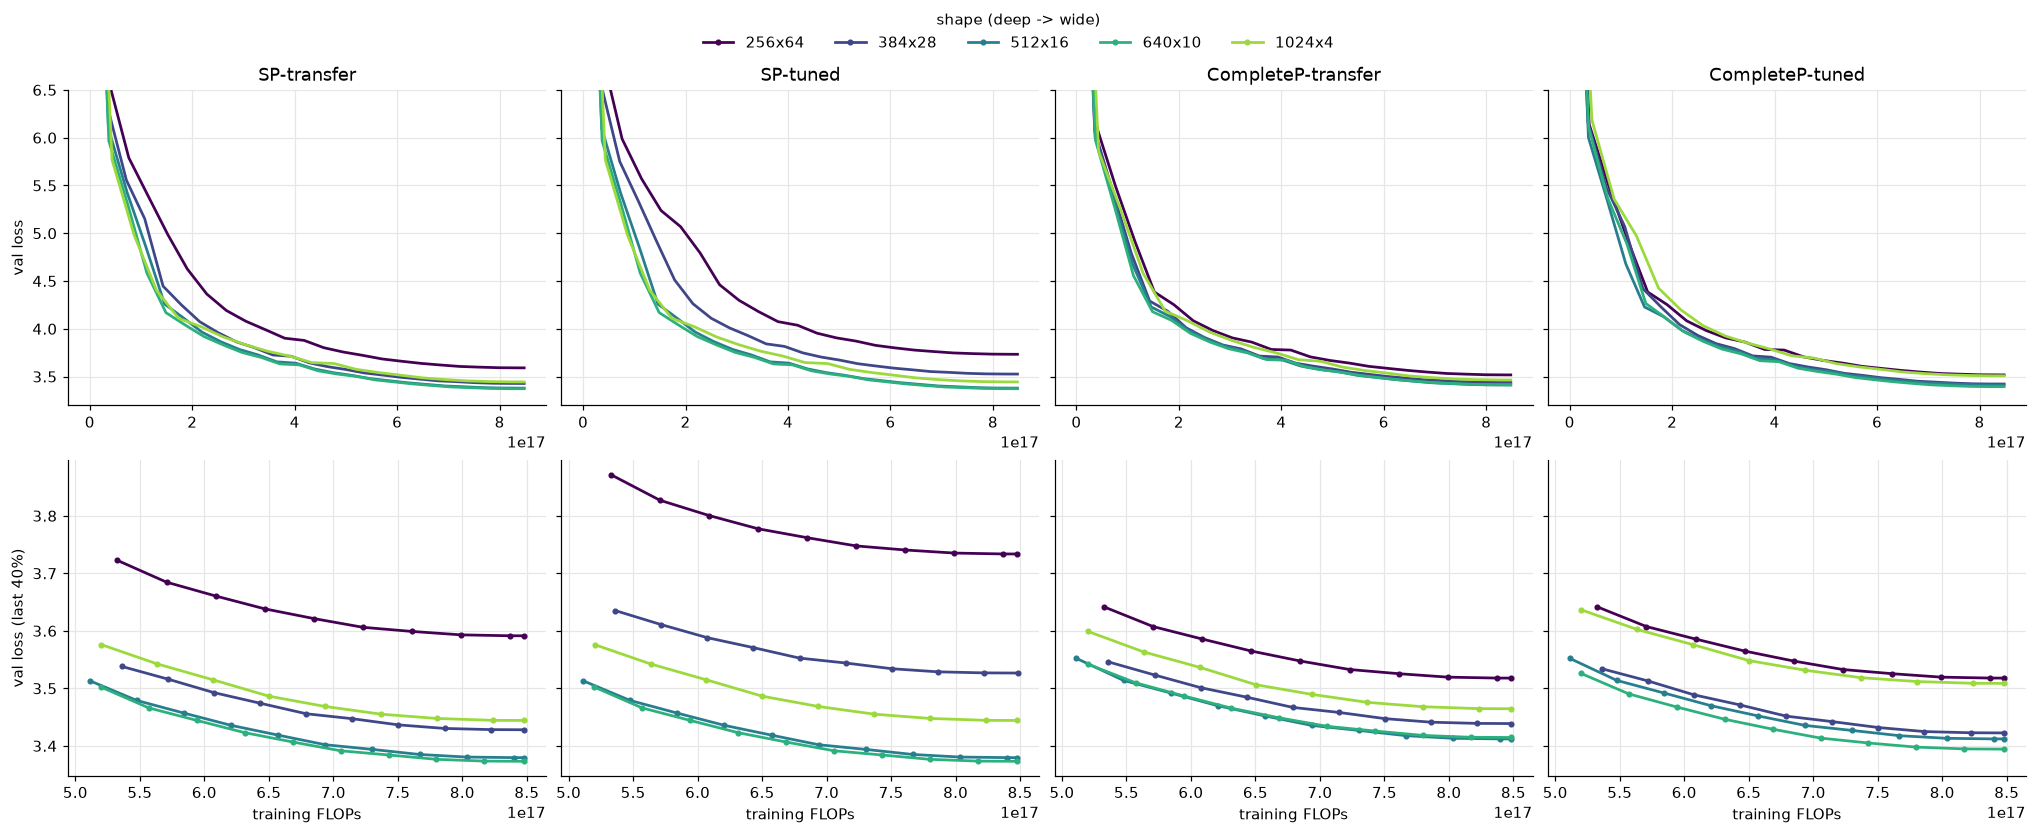

In [15]:
conds = [c for c in COND if any(run_of(c, s) is not None for s in SHAPES)]
fig, axes = plt.subplots(2, len(conds), figsize=(4.6 * len(conds), 7.5), sharey="row", squeeze=False,
                         constrained_layout=True)
for j, c in enumerate(conds):
    for s in SHAPES:
        r = run_of(c, s)
        if r is None:
            continue
        e = curve(r["name"])
        axes[0, j].plot(e["flops"], e["val_loss"], color=SHAPE_COLORS[s], linewidth=1.8, label=s)
        z = e[e["frac"] >= 0.6]
        axes[1, j].plot(z["flops"], z["val_loss"], color=SHAPE_COLORS[s], marker="o", markersize=3, linewidth=1.8, label=s)
    axes[0, j].set_title(COND[c])
    axes[1, j].set_xlabel("training FLOPs")
axes[0, 0].set_ylim(3.2, 6.5)
axes[0, 0].set_ylabel("val loss")
axes[1, 0].set_ylabel("val loss (last 40%)")
handles = {l: h for ax in axes.flat for h, l in zip(*ax.get_legend_handles_labels())}
fig.legend([handles[s] for s in SHAPES if s in handles], [s for s in SHAPES if s in handles],
           loc="outside upper center", ncol=5, title="shape (deep -> wide)")
plt.show()

Training loss (`train.csv`, mean over the step's micro-batches, logged every 10 steps), smoothed over 200 steps.
Each training token is seen once (sequential single pass), so this is an unbiased estimate of the loss on unseen data,
and much denser than the val evals. Spikes here that the val curve misses show up in section 5.

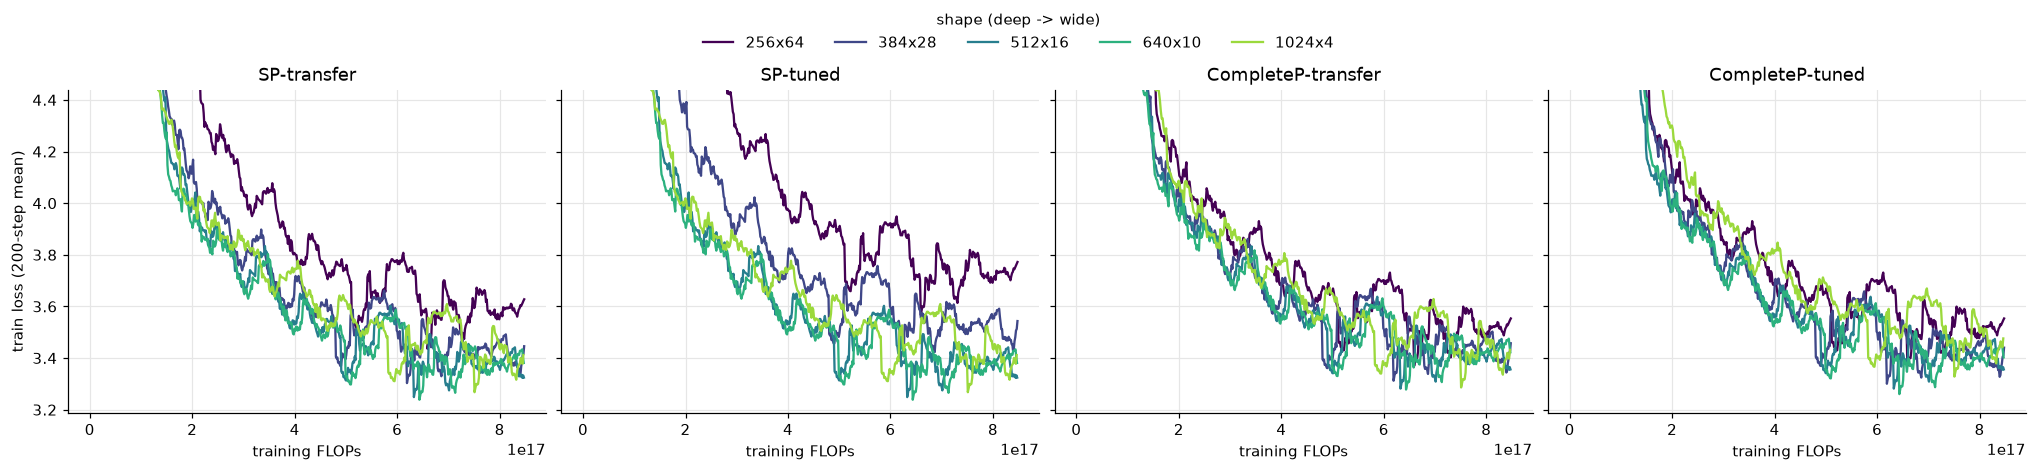

In [16]:
SMOOTH = 20  # logged rows (x 10 steps)
fig, axes = plt.subplots(1, len(conds), figsize=(4.6 * len(conds), 4.2), sharey=True, squeeze=False,
                         constrained_layout=True)
lows = []
for ax, c in zip(axes[0], conds):
    for s in SHAPES:
        r = run_of(c, s)
        if r is None:
            continue
        t = curve(r["name"], "train.csv")
        y = t["loss"].rolling(SMOOTH, min_periods=1).mean()
        ax.plot(t["flops"], y, color=SHAPE_COLORS[s], linewidth=1.5, label=s)
        lows.append(y.min())
    ax.set_title(COND[c])
    ax.set_xlabel("training FLOPs")
axes[0, 0].set_ylim(min(lows) - 0.05, min(lows) + 1.2)
axes[0, 0].set_ylabel(f"train loss ({SMOOTH * 10}-step mean)")
shape_legend(fig, axes)
plt.show()

### Against wall-clock

Same FLOPs do not mean same time: deep-narrow shapes run at lower MFU (section 4). Val loss against wall-clock hours
(`wall_time_s`, everything included), one panel per condition. The table gives each run's val loss at the
moment the fastest final run finished (dotted line; linear interpolation between evals): an iso-time comparison.

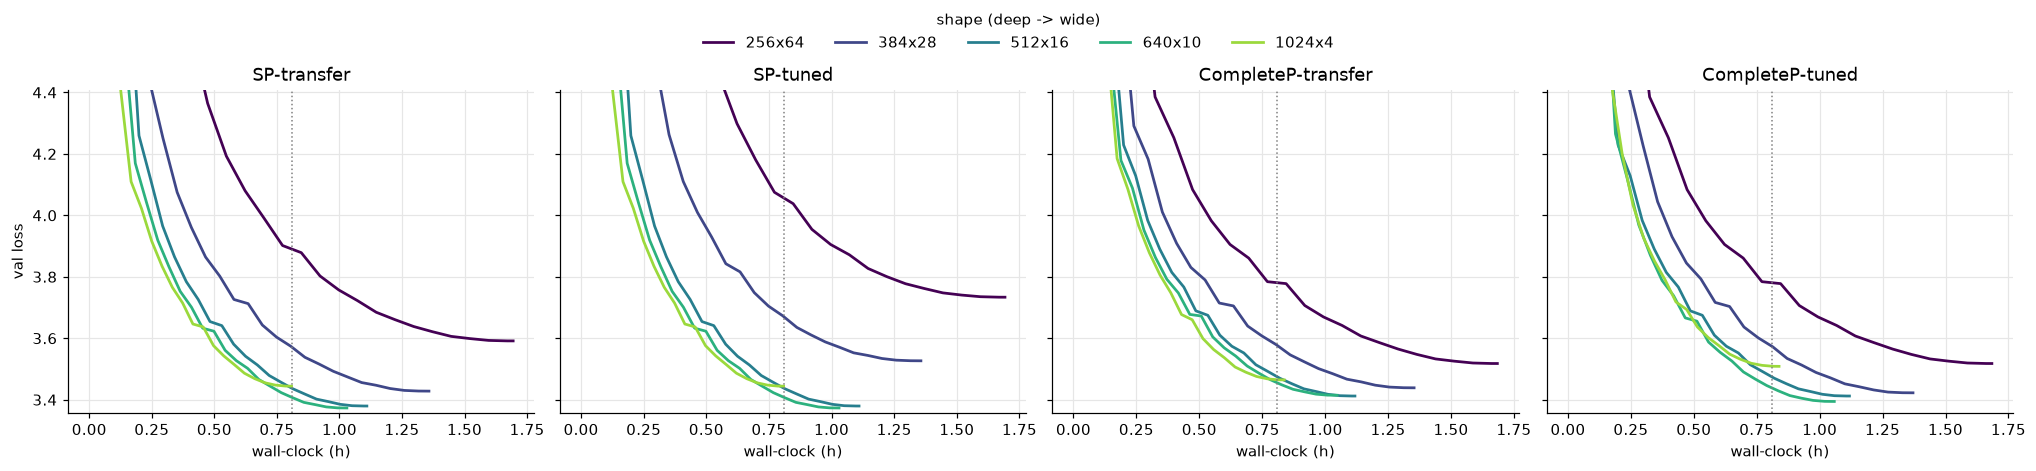

val loss at 0.81 h of wall-clock


,SP-transfer,SP-tuned,CompleteP-transfer,CompleteP-tuned
256x64,3.8904,4.0566,3.7809,3.7809
384x28,3.5718,3.6704,3.5771,3.5745
512x16,3.4378,3.4378,3.4750,3.4750
640x10,3.4081,3.4081,3.4553,3.4390
1024x4,3.4442,3.4442,3.4651,3.5092


In [17]:
fig, axes = plt.subplots(1, len(conds), figsize=(4.6 * len(conds), 4.2), sharey=True, squeeze=False,
                         constrained_layout=True)
iso = {}
t_star = final.loc[final["status"] == "finished", "wall_time_h"].min()
for ax, c in zip(axes[0], conds):
    curves = {s: curve(run_of(c, s)["name"]) for s in SHAPES if run_of(c, s) is not None}
    for s, e in curves.items():
        ax.plot(e["wall_time_s"] / 3600, e["val_loss"], color=SHAPE_COLORS[s], linewidth=1.8, label=s)
    ax.axvline(t_star, color="0.5", linestyle=":", linewidth=1)
    iso[COND[c]] = {s: np.interp(t_star * 3600, e["wall_time_s"], e["val_loss"]) for s, e in curves.items()}
    ax.set_title(COND[c])
    ax.set_xlabel("wall-clock (h)")
lo = min(v for d_ in iso.values() for v in d_.values())
axes[0, 0].set_ylim(lo - 0.05, lo + 1.0)
axes[0, 0].set_ylabel("val loss")
shape_legend(fig, axes)
plt.show()
print(f"val loss at {t_star:.2f} h of wall-clock")
pd.DataFrame(iso).reindex(SHAPES).round(4)

## 4. Throughput

From `runs.csv` (whole run): MFU (against the GPU's bf16 dense peak, $C_{tok} = 6P_{ne} + 6dV + 6LTd$), tokens/s,
training time (steps only) and wall-clock time. MFU depends on the shape, not the condition, so the lines should
nearly coincide; a gap between conditions at one shape means a slow node or a different GPU.

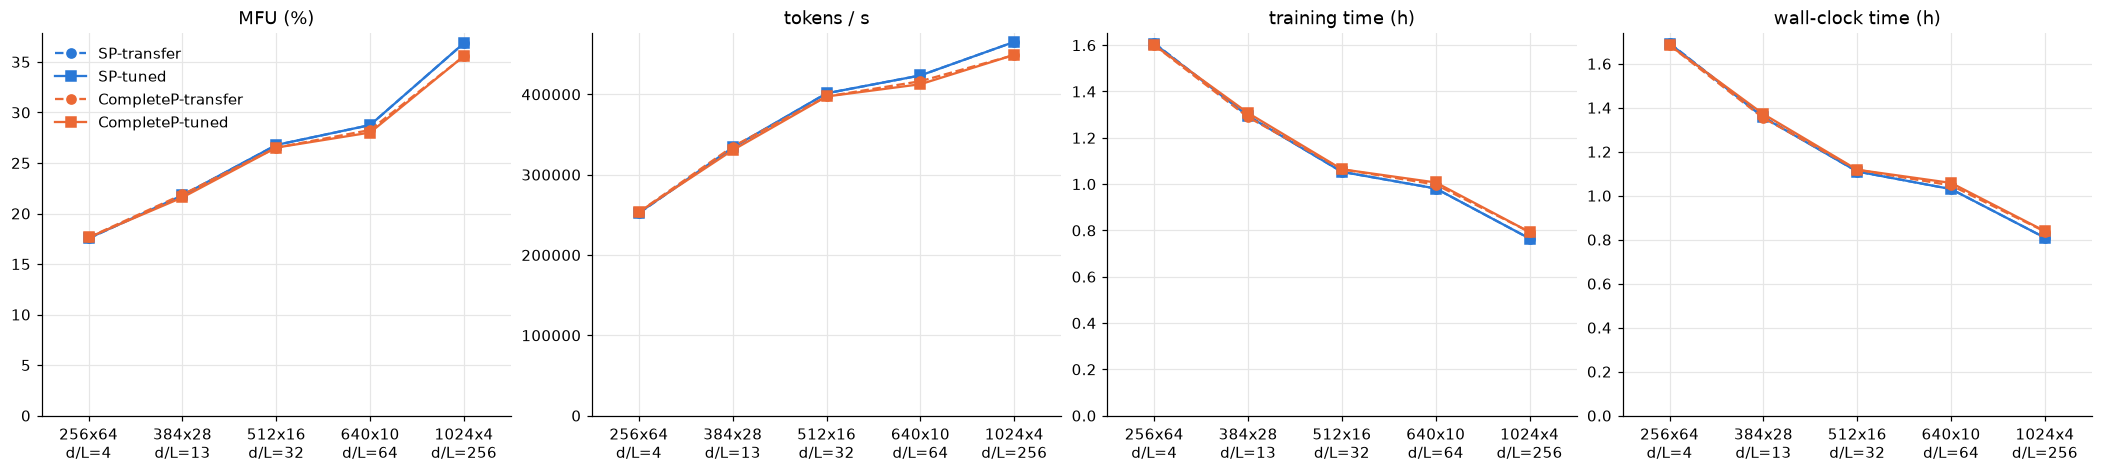

In [18]:
metrics = [("mfu", "MFU (%)"), ("tok_per_s", "tokens / s"), ("train_time_h", "training time (h)"),
           ("wall_time_h", "wall-clock time (h)")]
fig, axes = plt.subplots(1, 4, figsize=(19, 4.2), constrained_layout=True)
for ax, (col, label) in zip(axes, metrics):
    for c in COND:
        pts = [(X[s], run_of(c, s)[col]) for s in SHAPES if run_of(c, s) is not None]
        if pts:
            ax.plot(*zip(*pts), **STYLE[c], linewidth=1.5, markersize=6, label=COND[c])
    shape_axis(ax)
    ax.set_title(label)
    ax.set_ylim(bottom=0)
axes[0].legend()
plt.show()

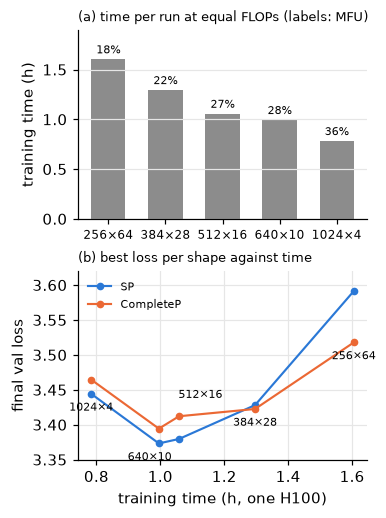

In [19]:
# Report figure: what each shape costs in time at equal FLOPs, and what it buys in loss
best = {"SP": ["a", "b"], "CompleteP": ["c", "d"]}
fin = final[final["status"] == "finished"]
hours = fin.groupby("shape")["train_time_h"].mean().reindex(SHAPES)
mfu = fin.groupby("shape")["mfu"].mean().reindex(SHAPES)

fig, axes = plt.subplots(2, 1, figsize=(3.4, 4.6), constrained_layout=True)
ax = axes[0]
bars = ax.bar(range(len(SHAPES)), mfu, color="0.55", width=0.6)
for b, m in zip(bars, mfu):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.6, f"{m:.0f}%", ha="center", va="bottom", fontsize=7.5)
ax.set_xticks(range(len(SHAPES)), [s.replace("x", "×") for s in SHAPES], fontsize=8)
ax.set_ylabel("MFU (%)")
ax.set_ylim(0, mfu.max() * 1.18)
ax.grid(axis="x", visible=False)
ax.set_title("(a) model FLOP utilisation per shape", fontsize=8.5, loc="left")

ax = axes[1]
for (p, cs), color in zip(best.items(), [BLUE, ORANGE]):
    loss = [min(run_of(c, s)["final_val_loss"] for c in cs if run_of(c, s) is not None) for s in SHAPES]
    ax.plot(hours, loss, color=color, marker="o", markersize=4, linewidth=1.4, label=p)
# label each shape just off its lower point; offsets (points) keep 640x10 and 512x16 apart
LABEL_AT = {"256x64": (0, -11), "384x28": (0, -11), "512x16": (14, 12), "640x10": (-6, -11), "1024x4": (0, -11)}
for s, x in hours.items():
    ys = [run_of(c, s)["final_val_loss"] for c in "abcd" if run_of(c, s) is not None]
    y = max(ys) if LABEL_AT[s][1] > 0 else min(ys)
    ax.annotate(s.replace("x", "×"), (x, y), textcoords="offset points", xytext=LABEL_AT[s], ha="center", fontsize=7)
ax.set_xlabel("training time (h, one H100)")
ax.set_ylabel("final val loss")
ax.set_ylim(3.35, 3.62)
ax.legend(fontsize=7.5, loc="upper left")
ax.set_title("(b) best loss per shape against time", fontsize=8.5, loc="left")
fig.savefig(RESULTS / "plots" / "throughput.pdf")
fig.savefig(RESULTS / "plots" / "throughput.png", dpi=200)
plt.show()

MFU over the course of each run (`train.csv`, averaged over each 10-step window, evals excluded).
It should be flat; dips are other jobs on the node, evals leaking into the window, or the first step (compile).

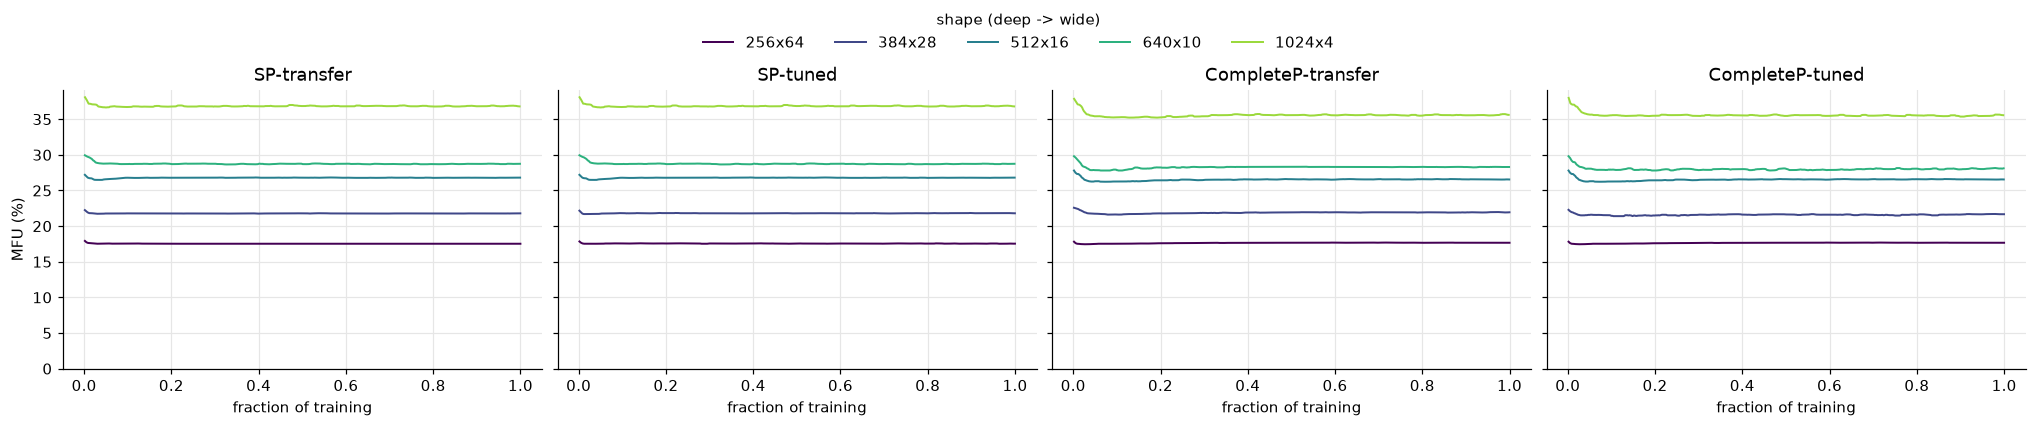

In [20]:
fig, axes = plt.subplots(1, len(conds), figsize=(4.6 * len(conds), 3.8), sharey=True, squeeze=False,
                         constrained_layout=True)
for ax, c in zip(axes[0], conds):
    for s in SHAPES:
        r = run_of(c, s)
        if r is None:
            continue
        t = curve(r["name"], "train.csv")
        ax.plot(t["frac"], t["mfu"].rolling(10, min_periods=1).median(), color=SHAPE_COLORS[s], linewidth=1.3, label=s)
    ax.set_title(COND[c])
    ax.set_xlabel("fraction of training")
axes[0, 0].set_ylabel("MFU (%)")
axes[0, 0].set_ylim(bottom=0)
shape_legend(fig, axes)
plt.show()

Memory and overheads per run: micro-batch x accumulation (always 128 sequences), peak GPU memory,
and the time outside training steps (evals every 250 steps, checkpoints, compile).

In [21]:
rows = []
for name, r in FINAL.iterrows():
    cfg = json.loads((RESULTS / "runs" / name / "config.json").read_text())
    t = load(name, "train.csv")
    rows.append({"name": name, "shape": r["shape"], "gpu": r["gpu"],
                 "micro-batch": cfg["batch_size"], "accumulation": cfg["gradient_accumulation_steps"],
                 "peak mem (GB)": t["peak_mem_gb"].max(),
                 "train (h)": r["train_time_h"], "wall (h)": r["wall_time_h"],
                 "overhead (h)": r["wall_time_h"] - r["train_time_h"],
                 "overhead (%)": 100 * (r["wall_time_h"] - r["train_time_h"]) / r["wall_time_h"],
                 "attempts": (RESULTS / "runs" / name / "run_info.txt").read_text().count("=== attempt")})
pd.DataFrame(rows).sort_values(["shape", "name"]).round(3).reset_index(drop=True)

,name,shape,gpu,micro-batch,accumulation,peak mem (GB),train (h),wall (h),overhead (h),overhead (%),attempts
0,completep-1024x4,1024x4,NVIDIA H100 NVL,32,4,33.657,0.793,0.837,0.044,5.257,1
1,completep-tuned-1024x4,1024x4,NVIDIA H100 NVL,32,4,33.657,0.793,0.839,0.046,5.483,1
2,sp-transfer-1024x4,1024x4,NVIDIA H100 NVL,32,4,33.657,0.765,0.809,0.044,5.439,1
3,completep-256x64,256x64,NVIDIA H100 NVL,16,8,34.018,1.600,1.684,0.084,4.988,1
4,sp-transfer-256x64,256x64,NVIDIA H100 NVL,16,8,34.018,1.609,1.694,0.085,5.018,1
5,sp-tuned-256x64,256x64,NVIDIA H100 NVL,16,8,34.018,1.607,1.692,0.085,5.024,1
6,completep-384x28,384x28,NVIDIA H100 NVL,16,8,26.391,1.289,1.353,0.064,4.730,1
7,completep-tuned-384x28,384x28,NVIDIA H100 NVL,16,8,26.391,1.307,1.371,0.064,4.668,1
8,sp-transfer-384x28,384x28,NVIDIA H100 NVL,16,8,26.391,1.295,1.358,0.063,4.639,1
9,sp-tuned-384x28,384x28,NVIDIA H100 NVL,16,8,26.391,1.294,1.356,0.062,4.572,1


## 5. Optimization

Global gradient norm before clipping (`train.csv` `grad_norm`, every 10th step), median over 100 steps, log scale.
The dotted line is the clip threshold (1.0): above it, the step was clipped.

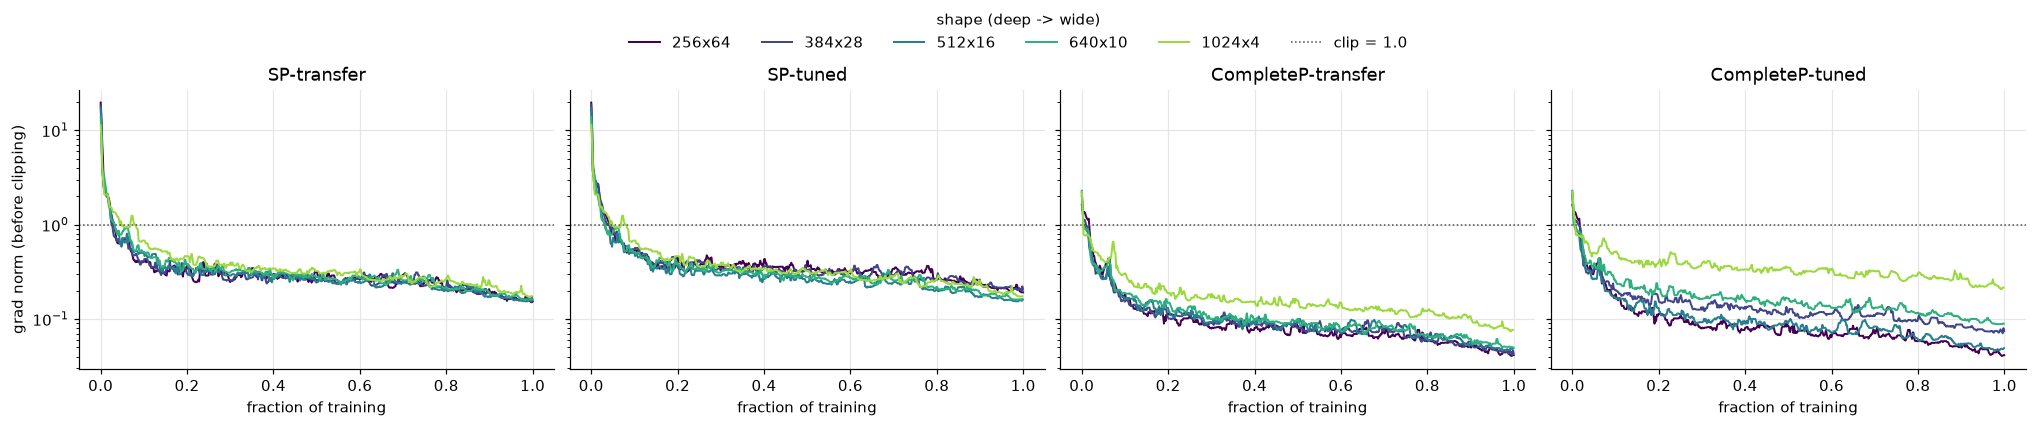

In [22]:
fig, axes = plt.subplots(1, len(conds), figsize=(4.6 * len(conds), 3.8), sharey=True, squeeze=False,
                         constrained_layout=True)
for ax, c in zip(axes[0], conds):
    for s in SHAPES:
        r = run_of(c, s)
        if r is None:
            continue
        t = curve(r["name"], "train.csv")
        ax.plot(t["frac"], t["grad_norm"].rolling(10, min_periods=1).median(), color=SHAPE_COLORS[s], linewidth=1.3, label=s)
    ax.axhline(1.0, color="0.3", linestyle=":", linewidth=1, label="clip = 1.0")
    ax.set_yscale("log")
    ax.set_title(COND[c])
    ax.set_xlabel("fraction of training")
axes[0, 0].set_ylabel("grad norm (before clipping)")
shape_legend(fig, axes)
plt.show()

Per run: how often the clip was active (share of logged steps with grad norm > 1, overall and after warmup),
the largest grad norm, and the largest **loss spike** (train loss above its own 200-step rolling median,
after warmup), and the step where it happened. All runs read the same tokens in the same order, so a spike at
the same step in every run is a hard batch of data, not an instability (the vertical stripes in the section 6
heatmaps are the same batches). A spike at a step no other run spikes at is the one to look at.

In [23]:
rows = []
for name, r in FINAL.iterrows():
    t = curve(name, "train.csv")
    post = t[t["frac"] > 0.1]
    excess = post["loss"] - post["loss"].rolling(20, min_periods=5, center=True).median()
    rows.append({"name": name, "condition": r["condition"], "shape": r["shape"],
                 "clipped (%)": 100 * (t["grad_norm"] > 1).mean(),
                 "clipped after warmup (%)": 100 * (post["grad_norm"] > 1).mean(),
                 "max grad norm": t["grad_norm"].max(),
                 "median grad norm (last 50%)": t.loc[t["frac"] > 0.5, "grad_norm"].median(),
                 "max loss spike": excess.max(), "spike at step": post.loc[excess.idxmax(), "iter"]})
pd.DataFrame(rows).sort_values(["shape", "name"]).round(4).reset_index(drop=True)

,name,condition,shape,clipped (%),clipped after warmup (%),max grad norm,median grad norm (last 50%),max loss spike,spike at step
0,completep-1024x4,c,1024x4,1.6360,0.6818,2.2135,0.1158,0.6524,4880
1,completep-tuned-1024x4,d,1024x4,2.8630,1.5909,6.6000,0.2822,0.6462,4880
2,sp-transfer-1024x4,a+b,1024x4,6.9530,1.8182,11.3106,0.2530,0.6363,4880
3,completep-256x64,c+d,256x64,1.4337,0.1992,1.9912,0.0615,0.6891,4880
4,sp-transfer-256x64,a,256x64,3.9427,0.9960,19.6071,0.2319,0.7511,1120
5,sp-tuned-256x64,b,256x64,5.3763,1.5936,19.6071,0.2860,0.8577,1120
6,completep-384x28,c,384x28,1.0101,0.3745,2.0161,0.0672,0.6741,4880
7,completep-tuned-384x28,d,384x28,1.5152,0.5618,2.5358,0.0996,0.6650,4880
8,sp-transfer-384x28,a,384x28,3.5354,0.9363,21.3796,0.2295,0.6624,4880
9,sp-tuned-384x28,b,384x28,5.5556,1.6854,18.5866,0.2783,0.7582,1120


LR schedule check: logged LR (`train.csv`, the base LR; CompleteP scales it per group) divided by its peak,
against fraction of training. Every run should follow the same curve: linear warmup over 10%, cosine to 0.

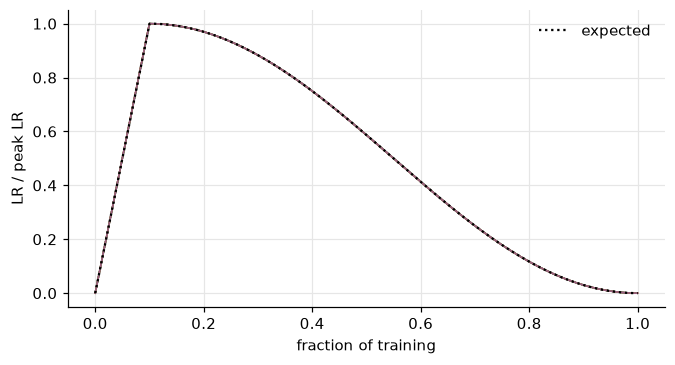

In [24]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for name in FINAL.index:
    t = curve(name, "train.csv")
    ax.plot(t["frac"], t["lr"] / t["lr"].max(), linewidth=1, alpha=0.6)
frac = np.linspace(0, 1, 500)
ref = np.where(frac < 0.1, frac / 0.1, 0.5 * (1 + np.cos(np.pi * (frac - 0.1) / 0.9)))
ax.plot(frac, ref, color="black", linestyle=":", linewidth=1.5, label="expected")
ax.set_xlabel("fraction of training")
ax.set_ylabel("LR / peak LR")
ax.legend()
plt.show()

## 6. Per-layer diagnostics

From `diag.csv`: every 100 steps (and the last step), one row per parameter tensor.
- `grad_rms`: RMS of the gradient Adam receives (mean over micro-batches, after clipping)
- `update_over_lr`: RMS of the actual parameter change divided by that tensor's LR. For Adam this is
  $\approx \mathrm{RMS}(\hat m / (\sqrt{\hat v} + \epsilon))$: about constant while $|g| \gg \epsilon$ (gradient scale cancels),
  and it collapses only if gradients approach $\epsilon$ (real starvation)
- `rel_update` = `update_rms / param_rms`: how much each step changes the weights, relatively
- `param_rms`: weight size

Hidden matrices (`attn.c_attn`, `attn.c_proj`, `mlp.c_fc`, `mlp.c_proj`) are combined by geometric mean;
LayerNorm gains, the embedding (`wte`, tied with the unembedding) and the final LN are shown separately.
Relative depth = (layer + 0.5) / L, so shapes of different depth share an x axis.

In [25]:
MATRIX = ["attn.c_attn", "attn.c_proj", "mlp.c_fc", "mlp.c_proj"]
NORMS = ["ln_1", "ln_2"]


@functools.cache
def diag(name):
    df = load(name, "diag.csv")
    if df is None:
        return None
    df = df.copy()
    df["frac"] = df["iter"] / FINAL.loc[name, "max_iters"]
    df["rel_update"] = df["update_rms"] / df["param_rms"]
    return df


def profile(name, metric, kinds=MATRIX, window=(0.1, 1.0)):
    """Per layer: geometric mean over kinds, then median over the evals in the window (fraction of training)."""
    df = diag(name)
    g = df[df["kind"].isin(kinds) & df["layer"].notna() & df["frac"].between(*window) & (df[metric] > 0)]
    v = g.assign(v=np.log10(g[metric])).groupby(["iter", "layer"])["v"].mean().groupby("layer").median()
    return (v.index.values + 0.5) / FINAL.loc[name, "L"], 10 ** v.values


no_diag = [n for n in FINAL.index if load(n, "diag.csv") is None]
print("runs without diag.csv:", no_diag or "none")

runs without diag.csv: none


### Depth profiles

Each metric against relative depth, median over training after warmup (10-100%). One panel per condition,
one line per shape. Gradient starvation would show as `grad_rms` falling with depth; whether it matters shows in
`update_over_lr` (falls only if Adam's normalization stops cancelling it).

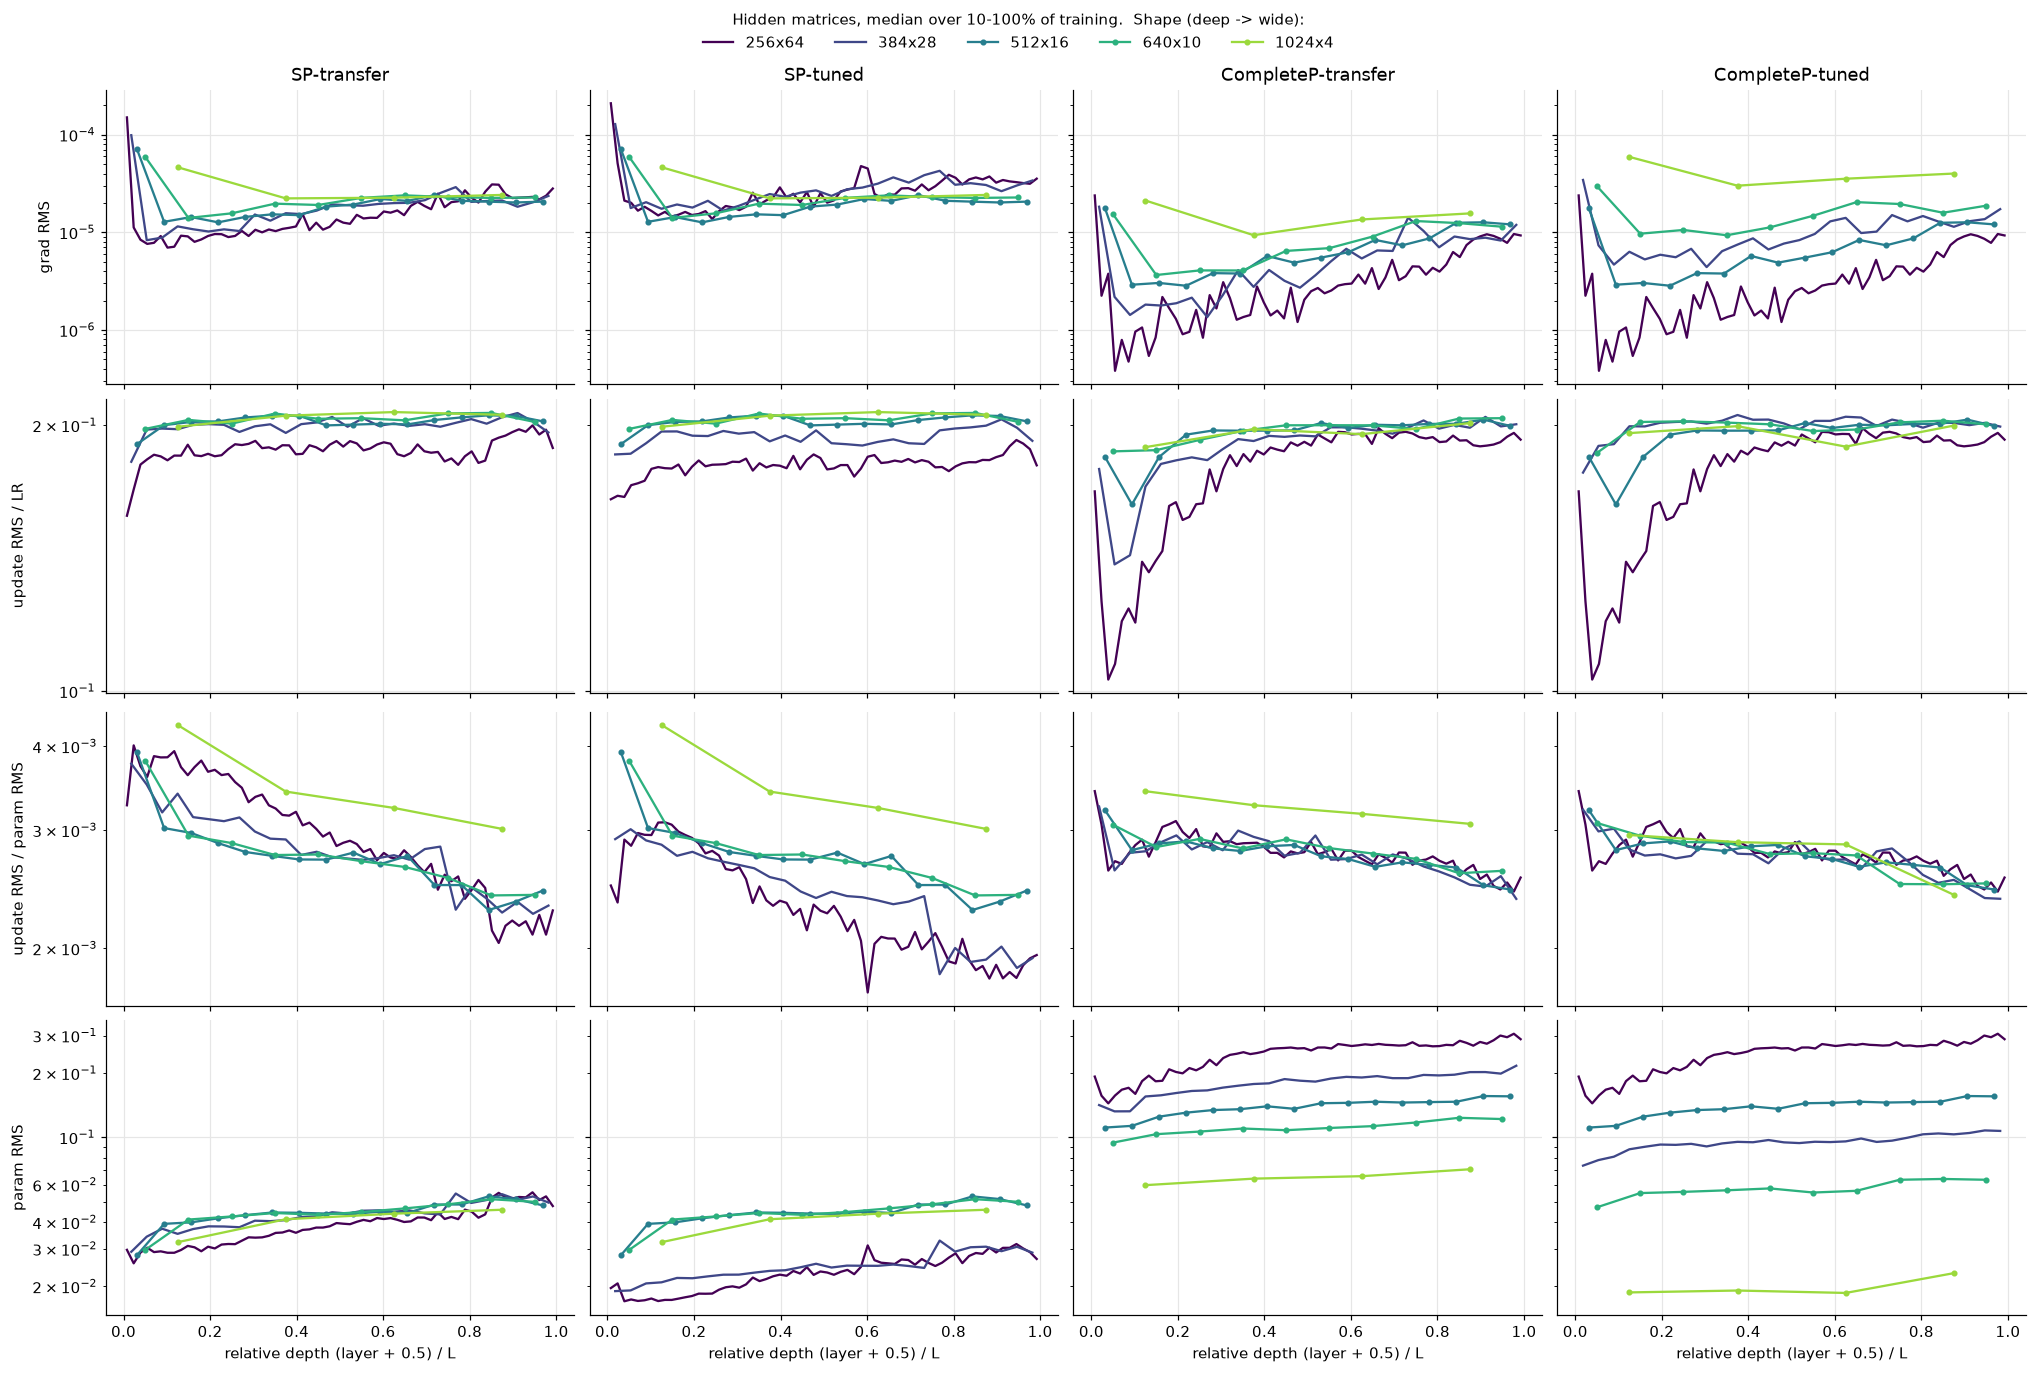

In [26]:
PROFILE_METRICS = [("grad_rms", "grad RMS"), ("update_over_lr", "update RMS / LR"),
                   ("rel_update", "update RMS / param RMS"), ("param_rms", "param RMS")]


def profile_grid(window, kinds=MATRIX, metrics=PROFILE_METRICS, title=""):
    fig, axes = plt.subplots(len(metrics), len(conds), figsize=(4.6 * len(conds), 3.1 * len(metrics)),
                             sharex=True, sharey="row", squeeze=False, constrained_layout=True)
    for j, c in enumerate(conds):
        for s in SHAPES:
            r = run_of(c, s)
            if r is None or diag(r["name"]) is None:
                continue
            for i, (m, _) in enumerate(metrics):
                x, y = profile(r["name"], m, kinds, window)
                axes[i, j].plot(x, y, color=SHAPE_COLORS[s], marker="o" if L[s] <= 16 else None,
                                markersize=3, linewidth=1.5, label=s)
        axes[0, j].set_title(COND[c])
        axes[-1, j].set_xlabel("relative depth (layer + 0.5) / L")
    for i, (_, label) in enumerate(metrics):
        axes[i, 0].set_yscale("log")
        axes[i, 0].set_ylabel(label)
    shape_legend(fig, axes, title=f"{title}.  Shape (deep -> wide):")
    plt.show()


profile_grid((0.1, 1.0), title="Hidden matrices, median over 10-100% of training")

Same profiles during warmup (1-10% of training) for the gradient, where deep models are most fragile,
and for the LayerNorm gains after warmup.

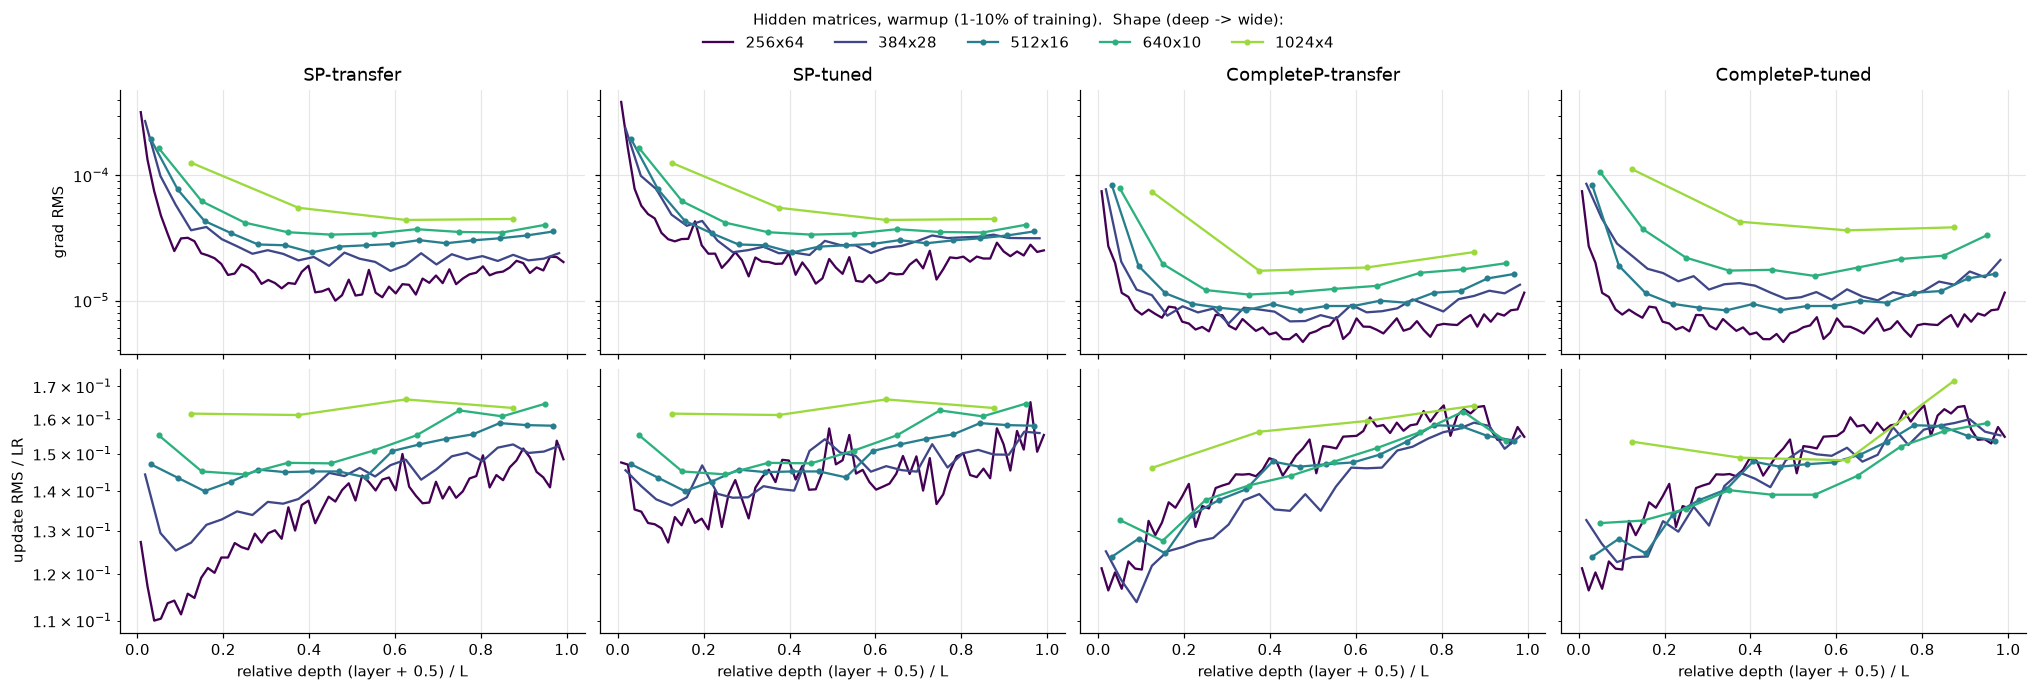

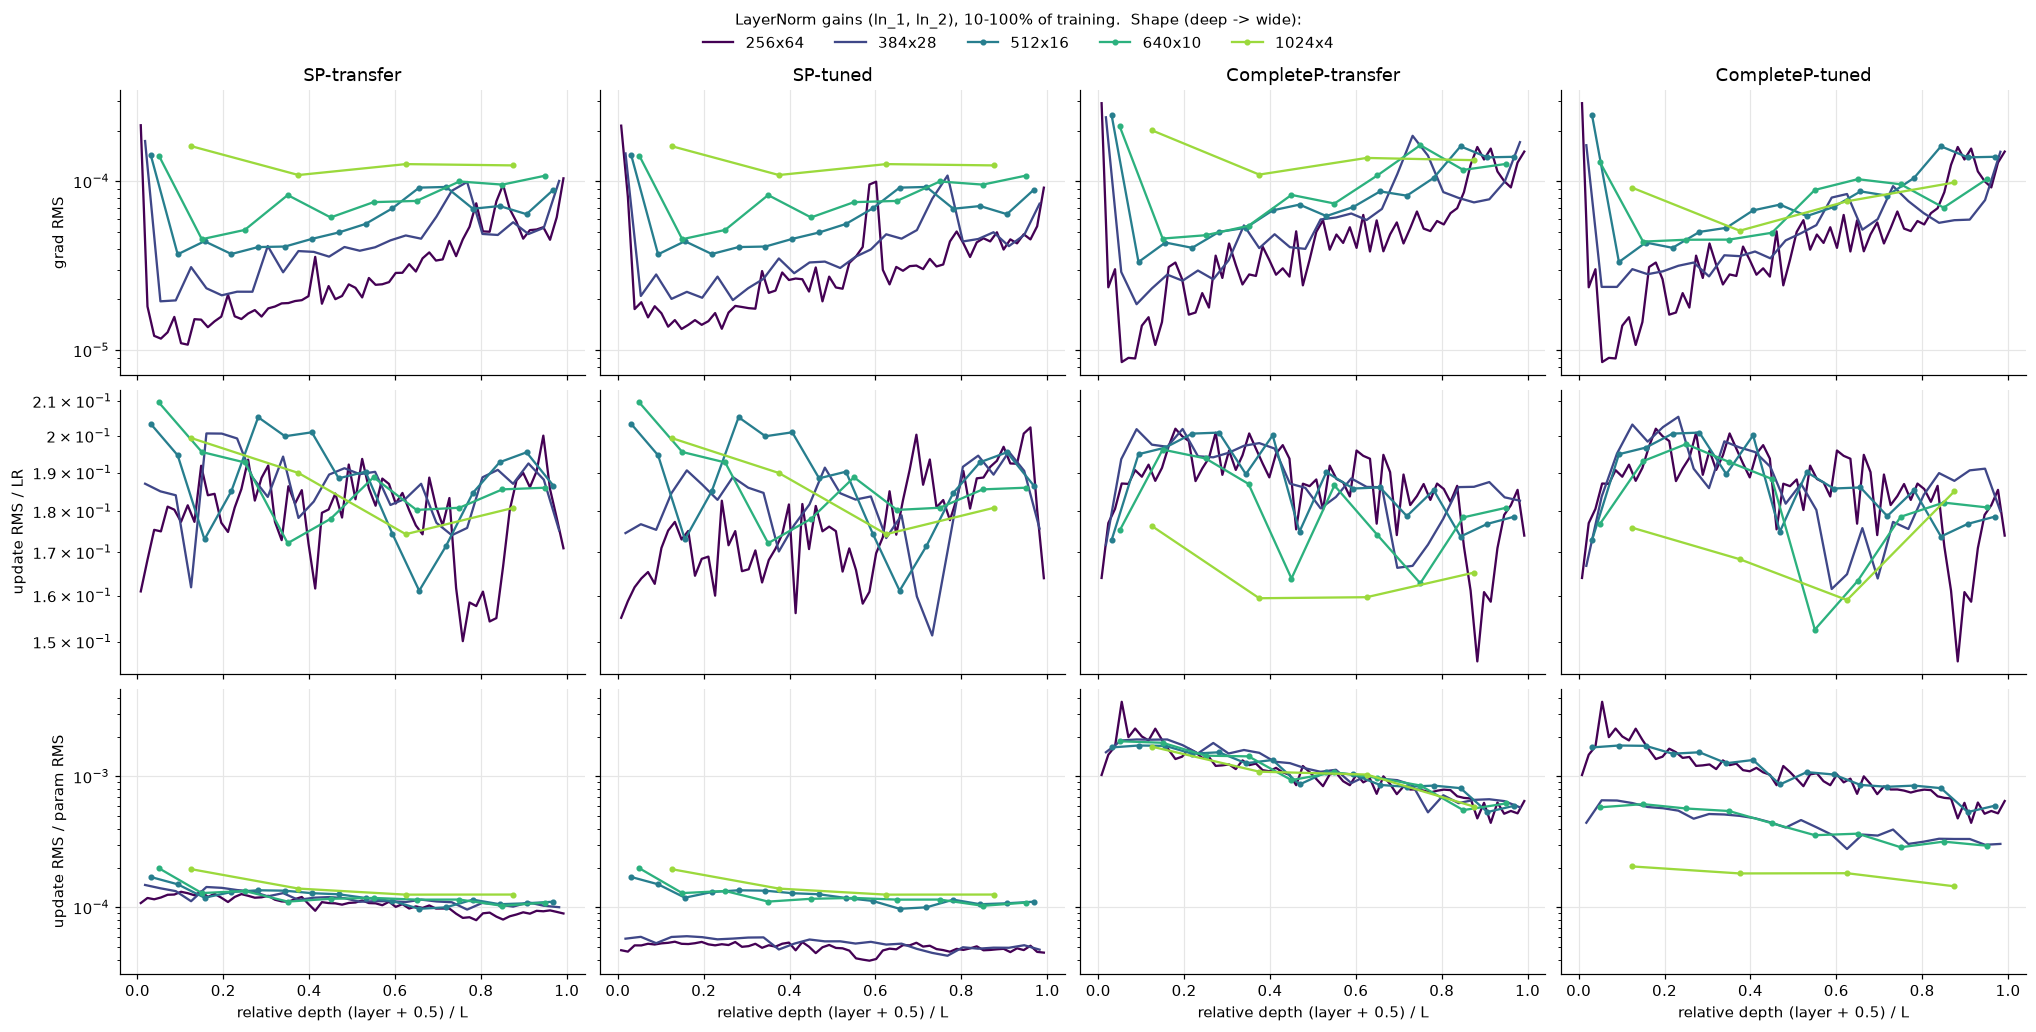

In [27]:
profile_grid((0.01, 0.1), metrics=PROFILE_METRICS[:2], title="Hidden matrices, warmup (1-10% of training)")
profile_grid((0.1, 1.0), kinds=NORMS, metrics=PROFILE_METRICS[:3], title="LayerNorm gains (ln_1, ln_2), 10-100% of training")

### Over training: layer x time heatmaps

log10 of the metric for every layer (y, 0 = first block) and every logged step (x, fraction of training),
hidden matrices combined. Rows = conditions, columns = shapes; one color scale per row.

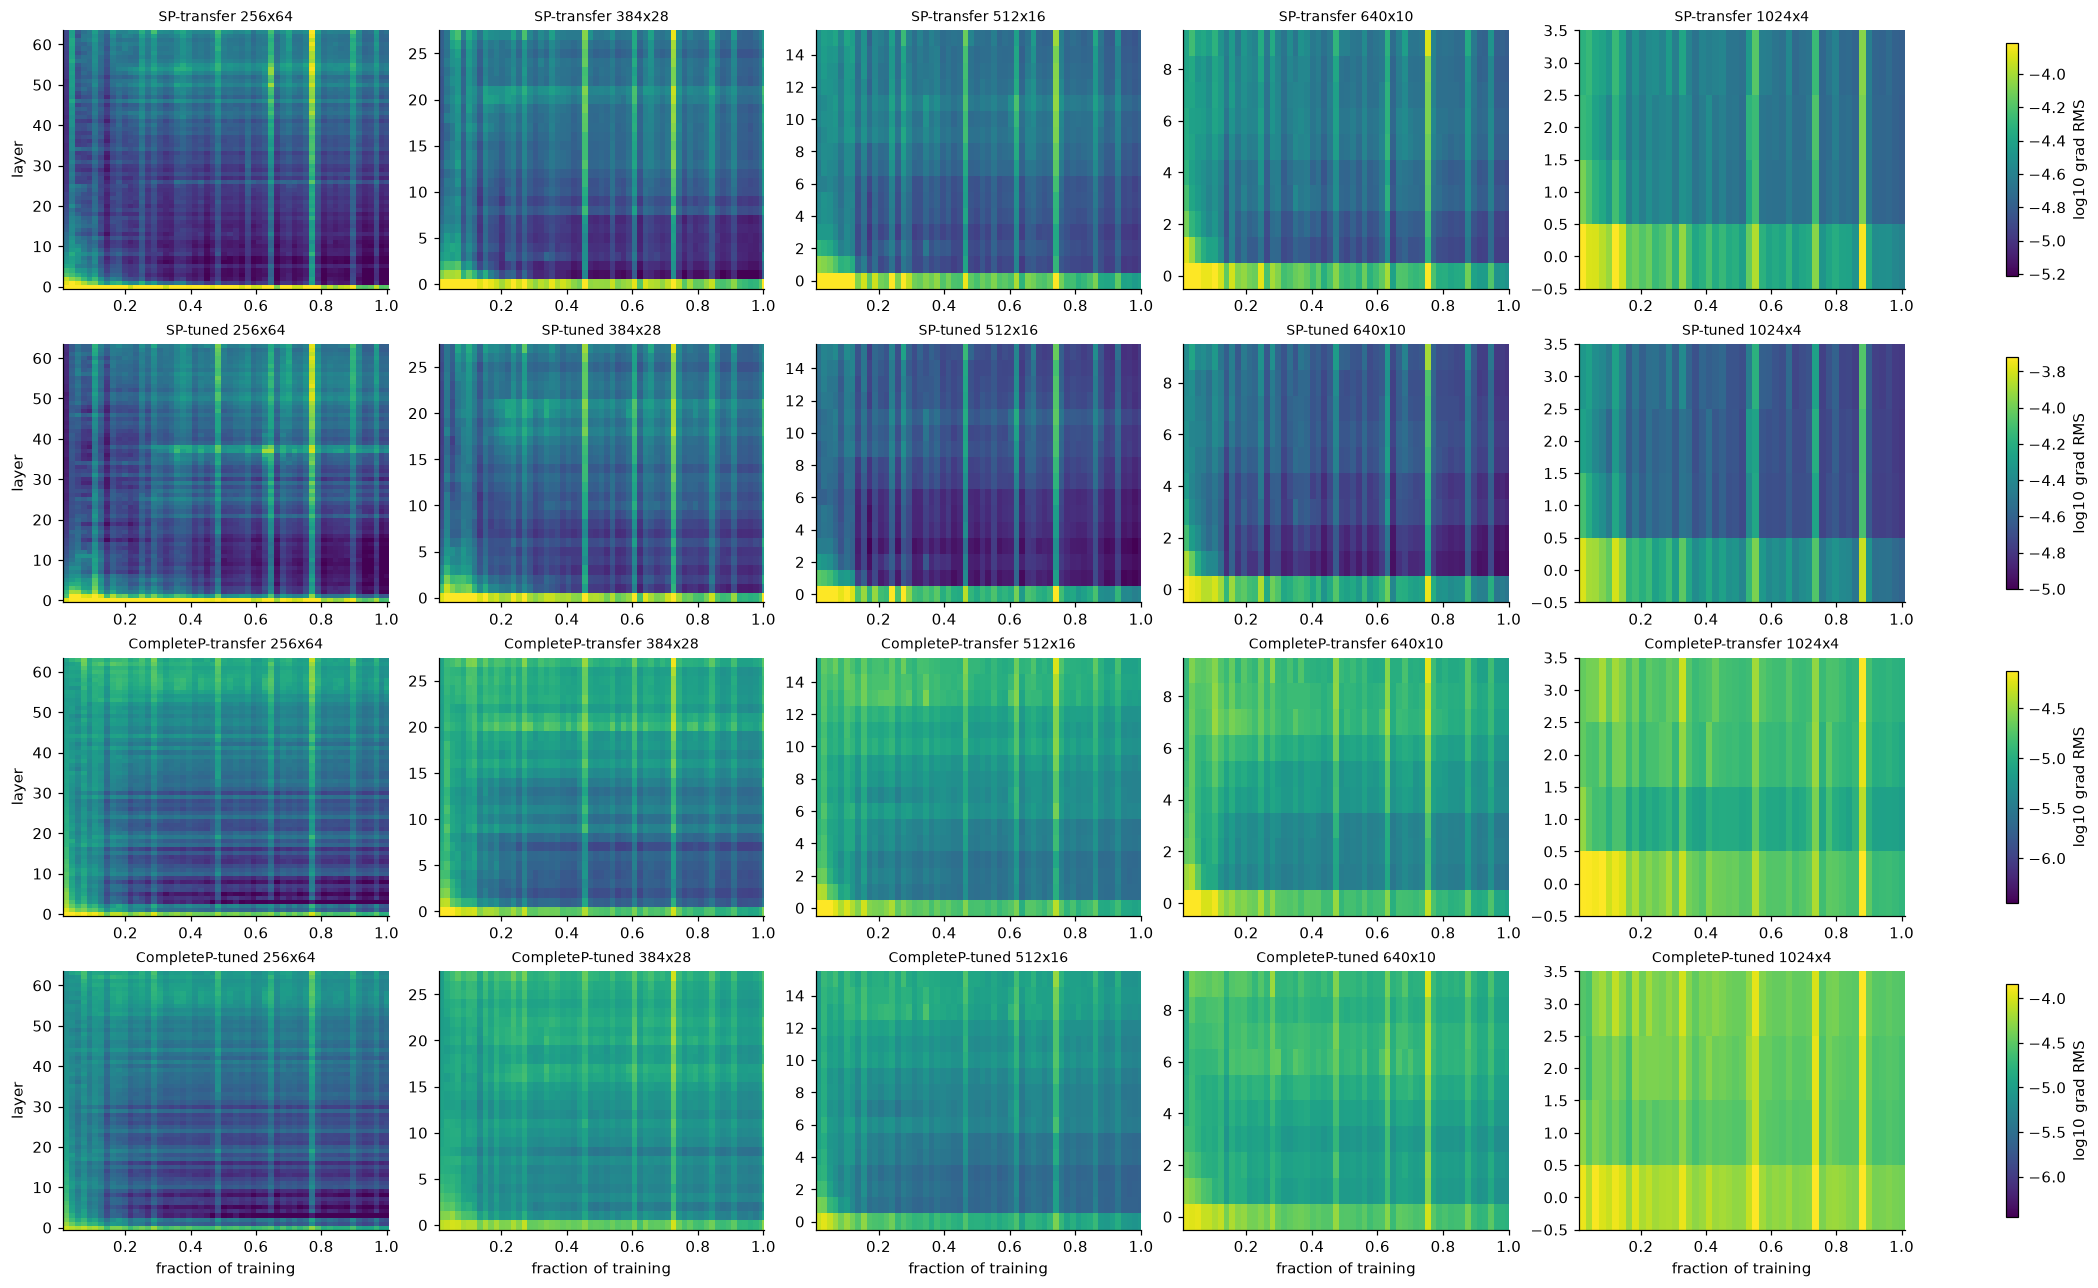

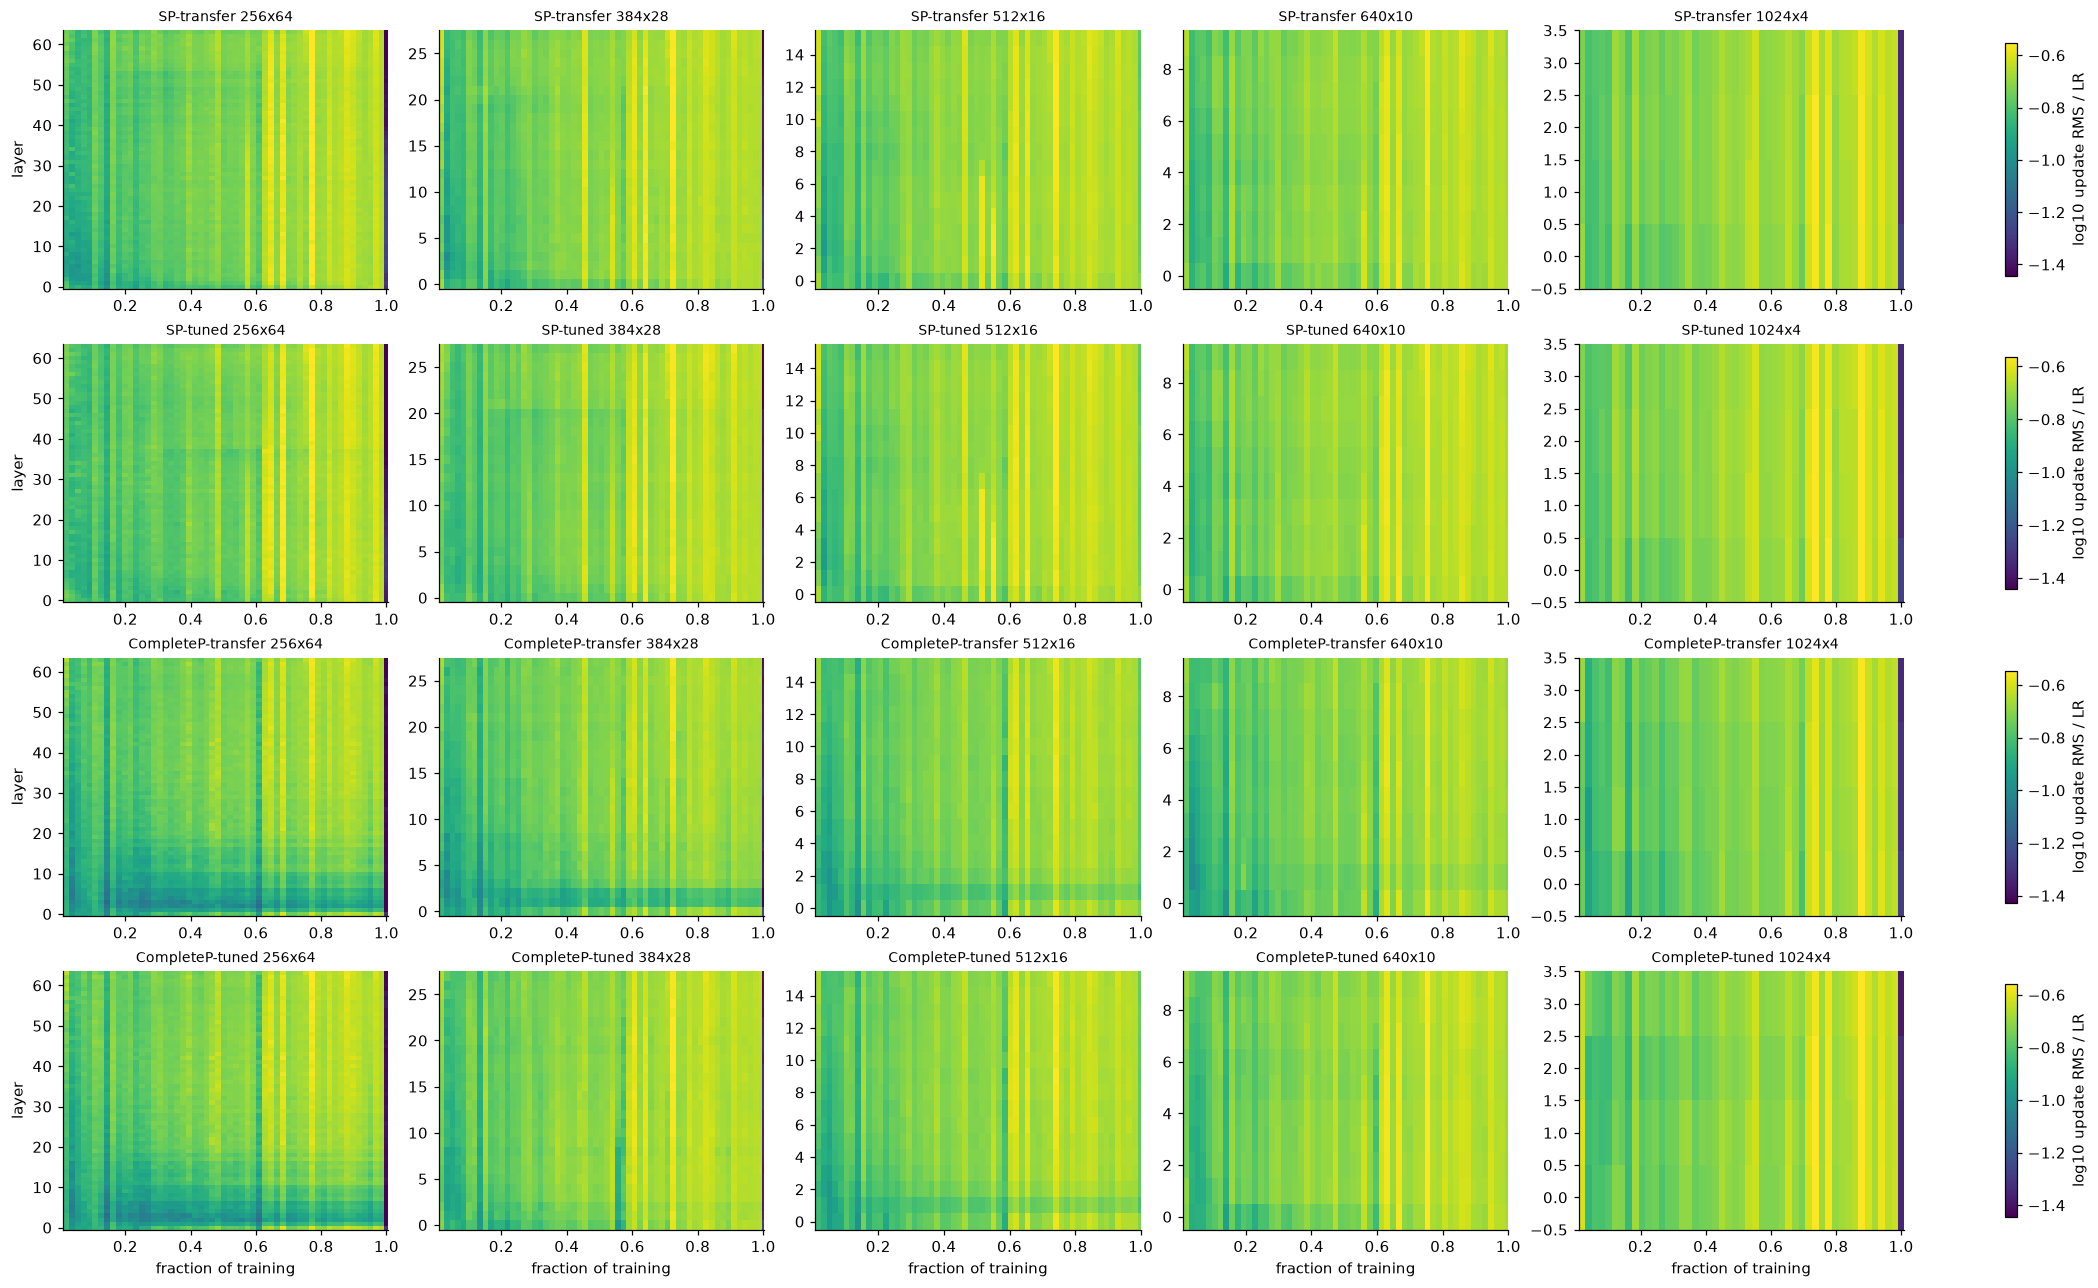

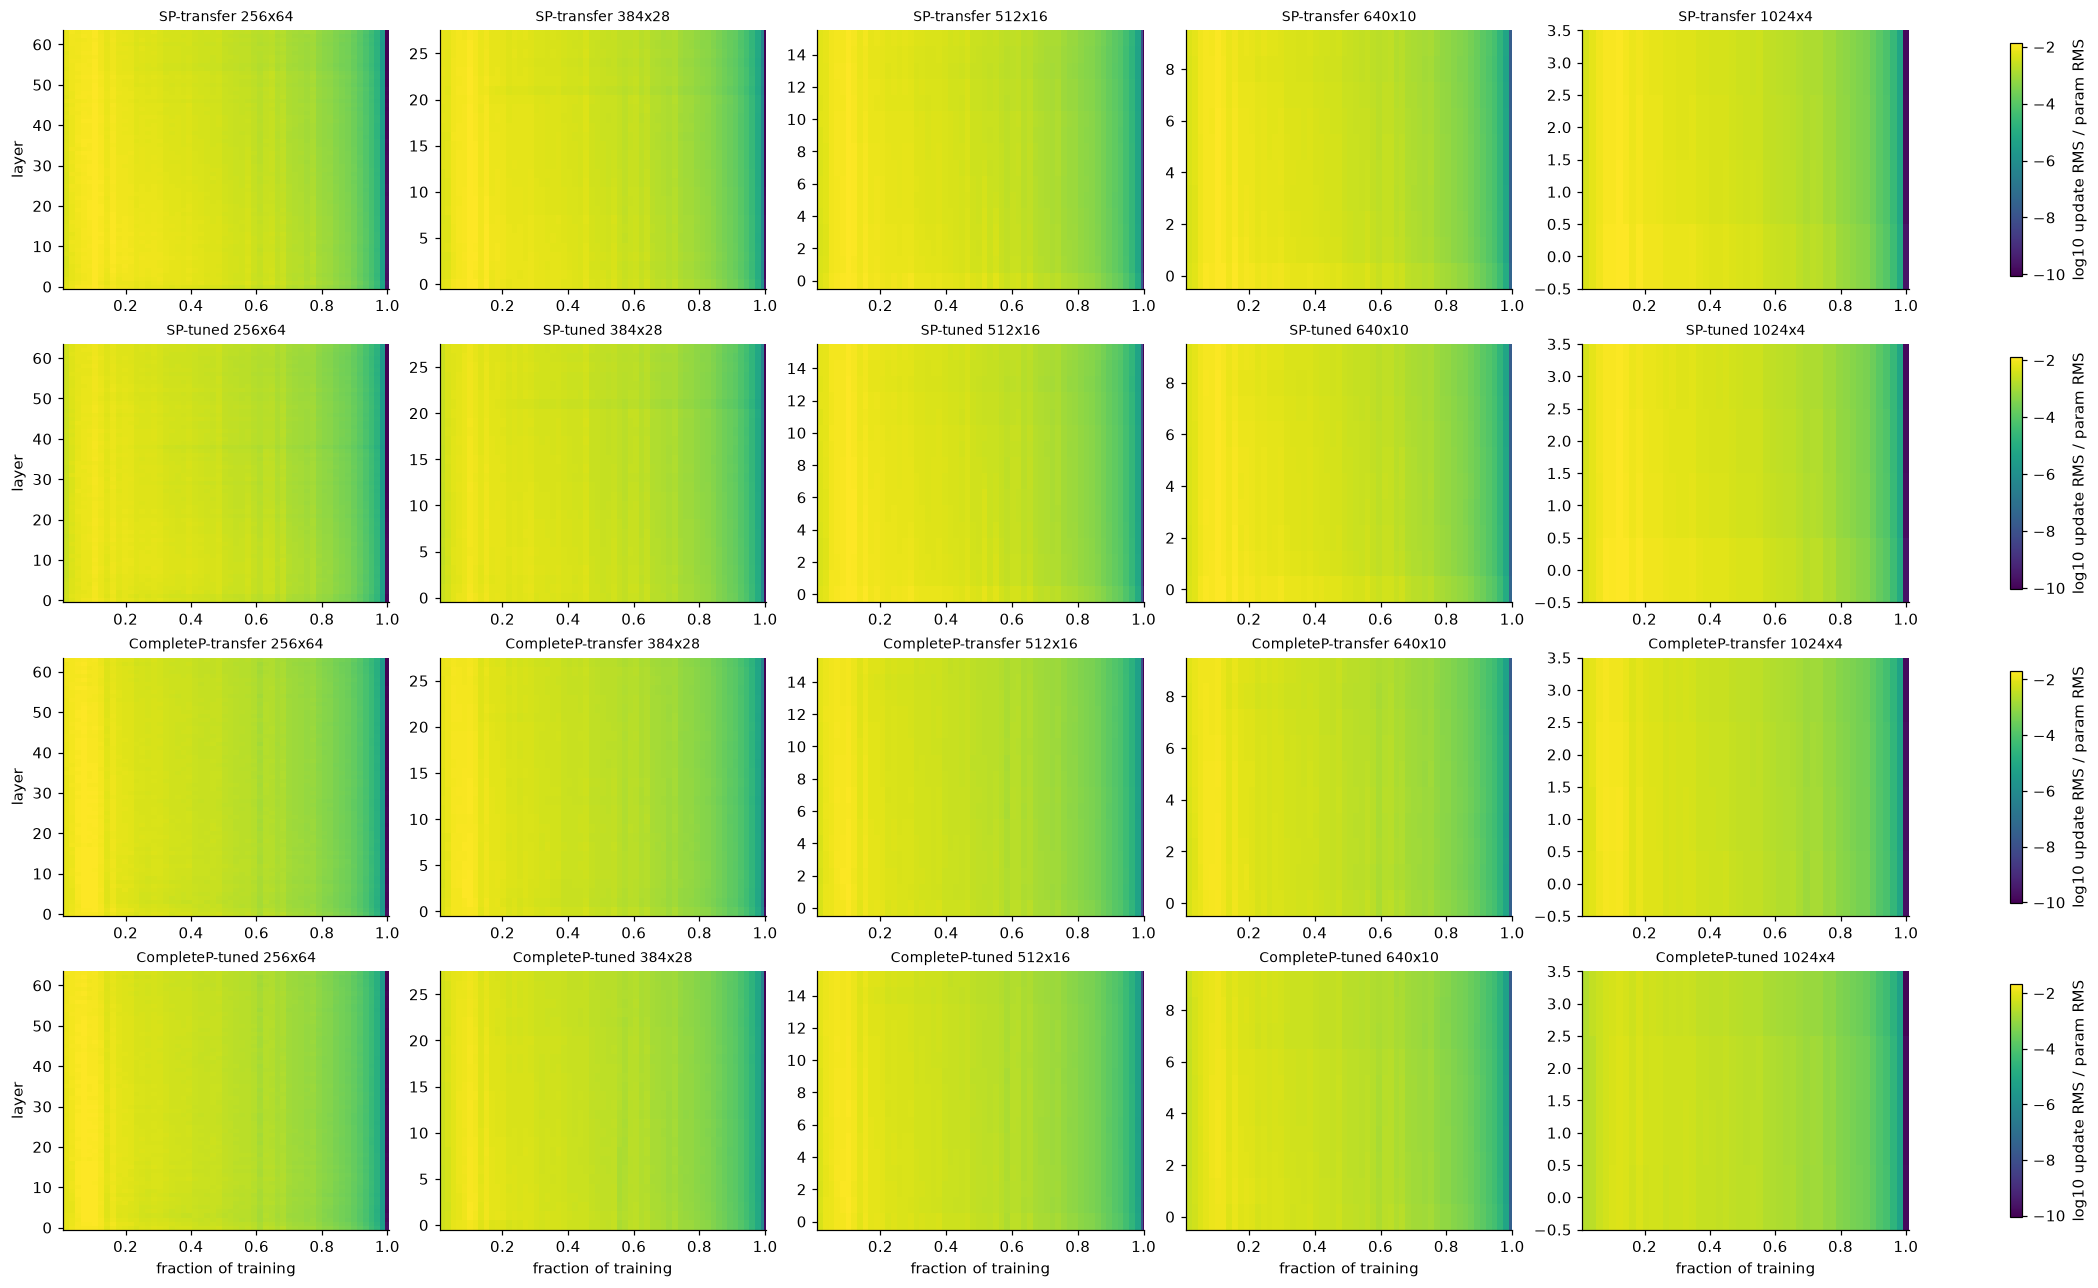

In [28]:
def heatmap_grid(metric, label, kinds=MATRIX, cond_list=None, log=True, vrange=None):
    cond_list = cond_list or conds
    grids = {}
    for c in cond_list:
        for s in SHAPES:
            r = run_of(c, s)
            if r is None or diag(r["name"]) is None:
                continue
            df = diag(r["name"])
            g = df[df["kind"].isin(kinds) & df["layer"].notna() & (df["iter"] > 0)]
            if log:
                g = g[g[metric] > 0]
            grids[c, s] = g.assign(v=np.log10(g[metric]) if log else g[metric]).pivot_table(index="layer", columns="frac", values="v", aggfunc="mean")
    fig, axes = plt.subplots(len(cond_list), len(SHAPES), figsize=(19, 2.9 * len(cond_list)), squeeze=False,
                             constrained_layout=True)
    for i, c in enumerate(cond_list):
        row = [m for (cc, _), m in grids.items() if cc == c]
        if not row:
            for ax in axes[i]:
                ax.set_visible(False)
            continue
        vmin, vmax = vrange or (min(np.nanpercentile(m.values, 1) for m in row),
                                max(np.nanpercentile(m.values, 99) for m in row))
        for j, s in enumerate(SHAPES):
            ax = axes[i, j]
            if (c, s) not in grids:
                ax.set_visible(False)
                continue
            m = grids[c, s]
            im = ax.pcolormesh(m.columns, m.index, m.values, shading="nearest", cmap="viridis", vmin=vmin, vmax=vmax)
            ax.grid(False)
            ax.set_title(f"{COND[c]} {s}", fontsize=9)
            if j == 0:
                ax.set_ylabel("layer")
            if i == len(cond_list) - 1:
                ax.set_xlabel("fraction of training")
        fig.colorbar(im, ax=axes[i, :], label=f"log10 {label}" if log else label, shrink=0.9)
    plt.show()


heatmap_grid("grad_rms", "grad RMS")
heatmap_grid("update_over_lr", "update RMS / LR")
heatmap_grid("rel_update", "update RMS / param RMS")

### Zero gradients in the MLPs

Fraction of entries with $|g| < \epsilon$ (linear scale, 0 to 1), for the MLP input (`mlp.c_fc`) and output
(`mlp.c_proj`) matrices. $\epsilon \le 10^{-16}$ while a typical entry is ~$10^{-6}$-$10^{-4}$, so these entries get
essentially no gradient. Whole rows of `c_fc` and columns of `c_proj` at once point to MLP units whose GELU input is
very negative for every token (GELU's gradient there is ~0): dead units, which then also get no Adam update
(`frac_sqrtv_below_eps` follows the same pattern). Logging the pre-activations would confirm it.

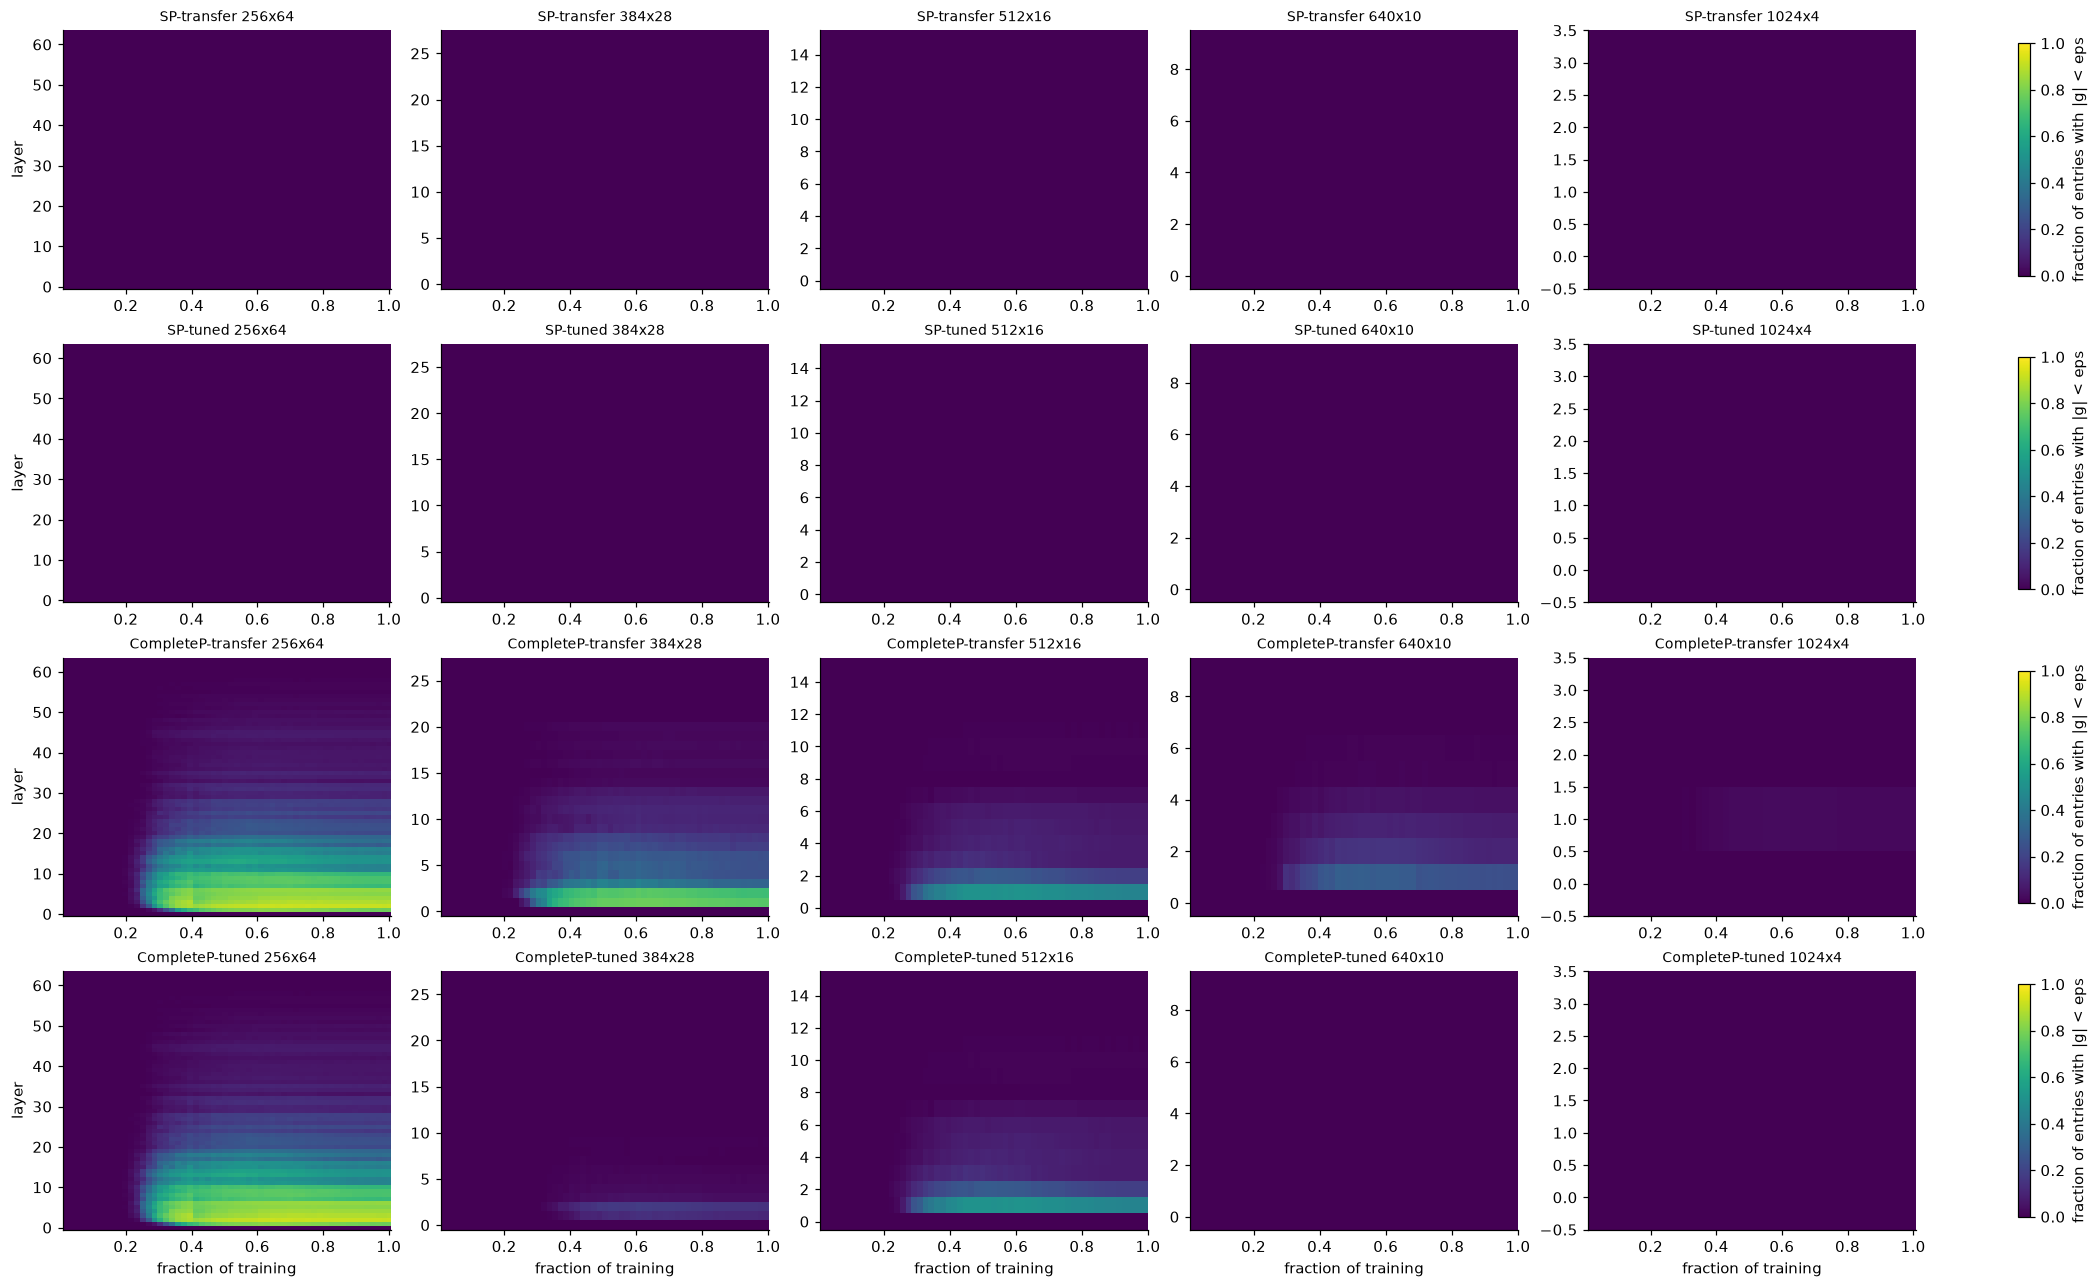

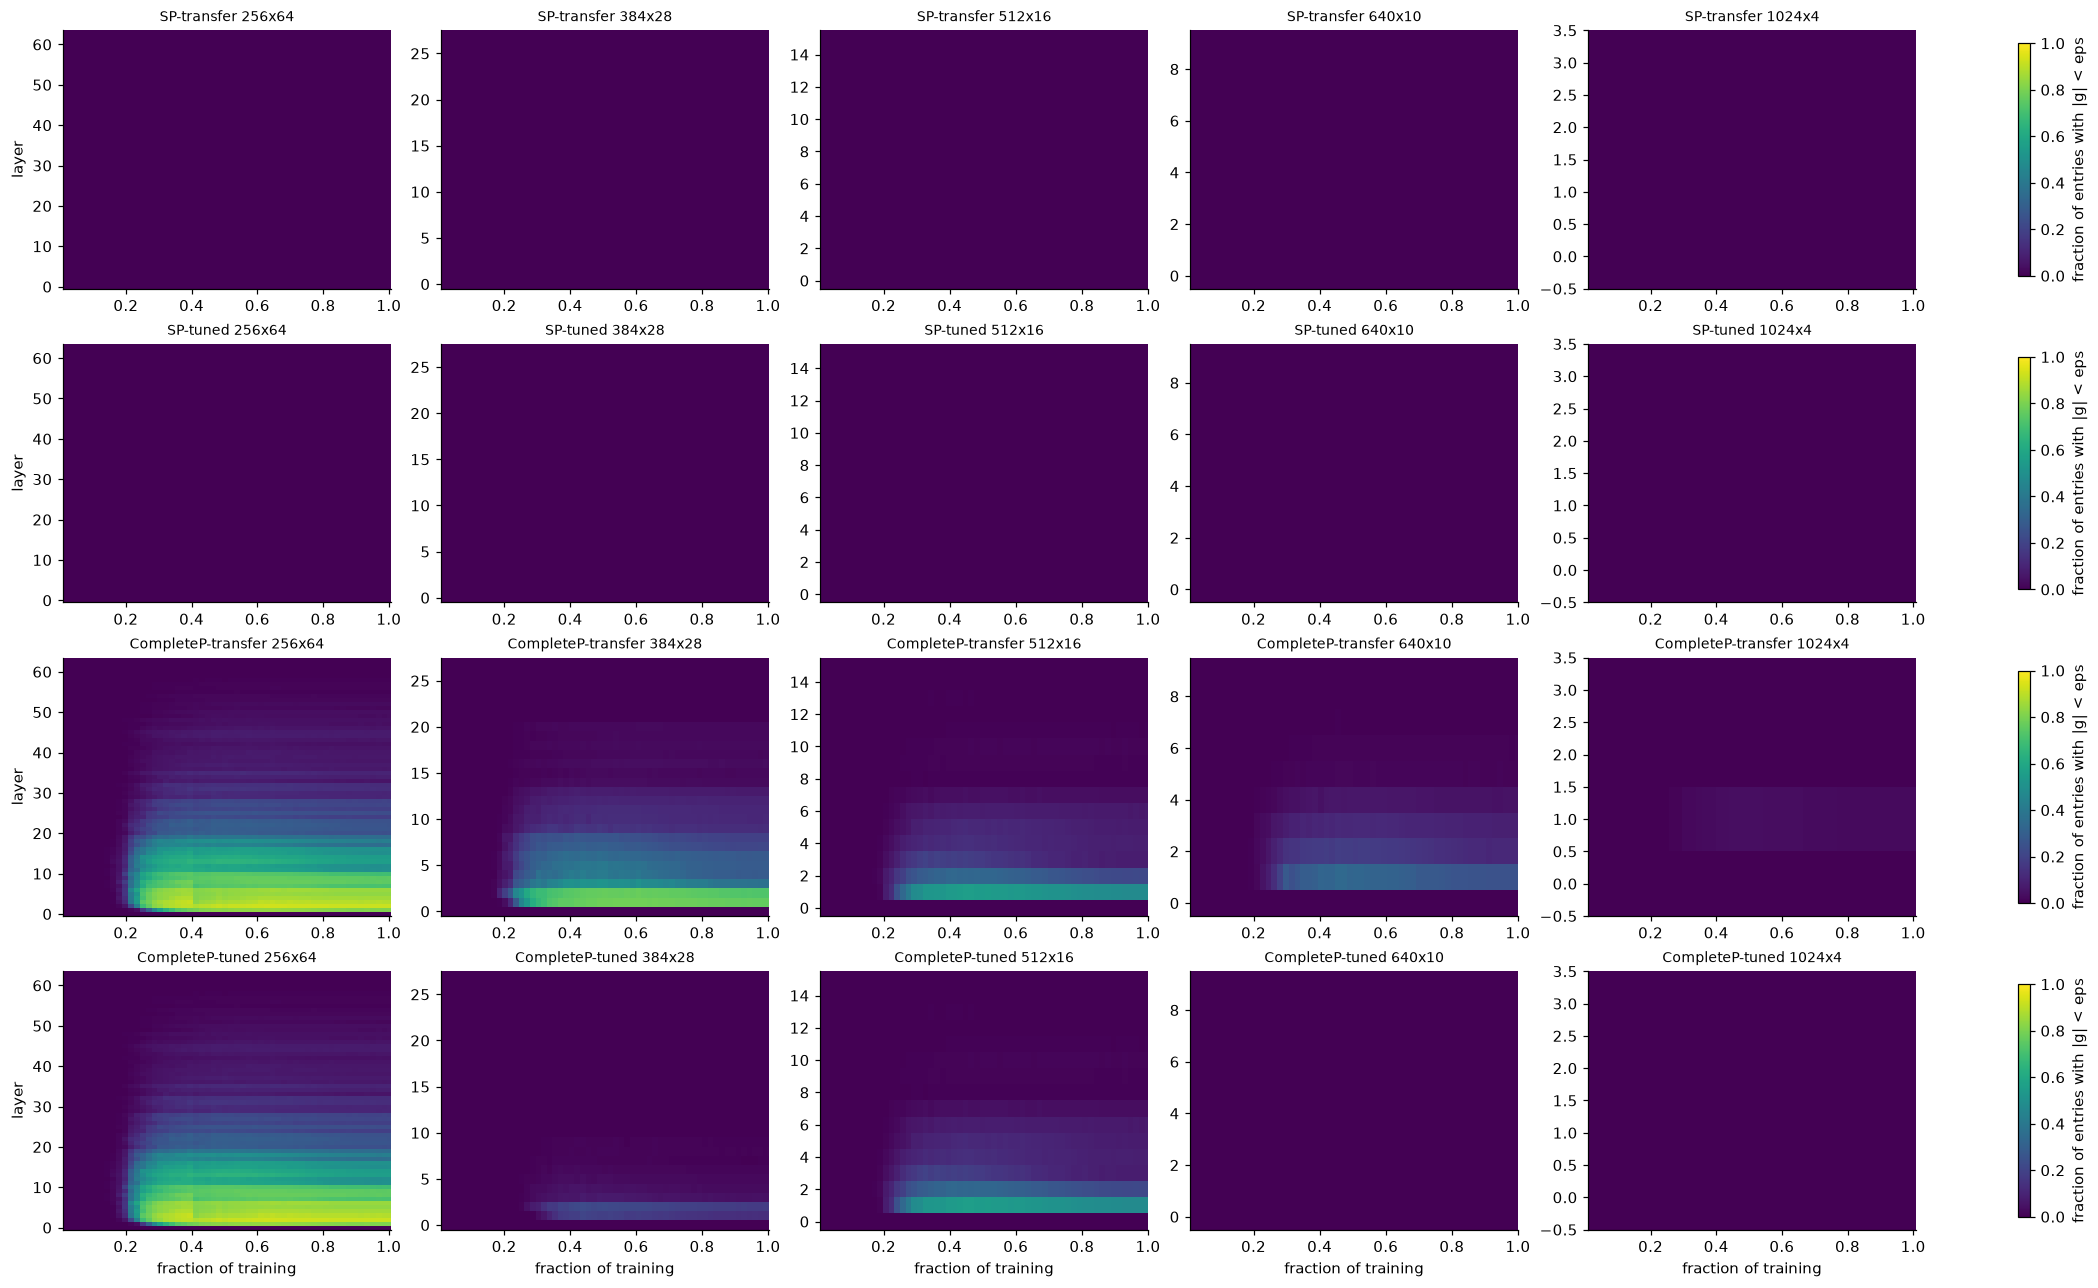

In [29]:
heatmap_grid("frac_g_below_eps", "fraction of entries with |g| < eps", kinds=["mlp.c_fc"], log=False, vrange=(0, 1))
heatmap_grid("frac_g_below_eps", "fraction of entries with |g| < eps", kinds=["mlp.c_proj"], log=False, vrange=(0, 1))

### Per kind of tensor

Depth profile (10-100% of training) split by tensor kind, for one shape (`KIND_SHAPE`, default the deepest),
lines = conditions. Shows which part of the block (attention in/out, MLP in/out, LayerNorms) carries any depth trend.

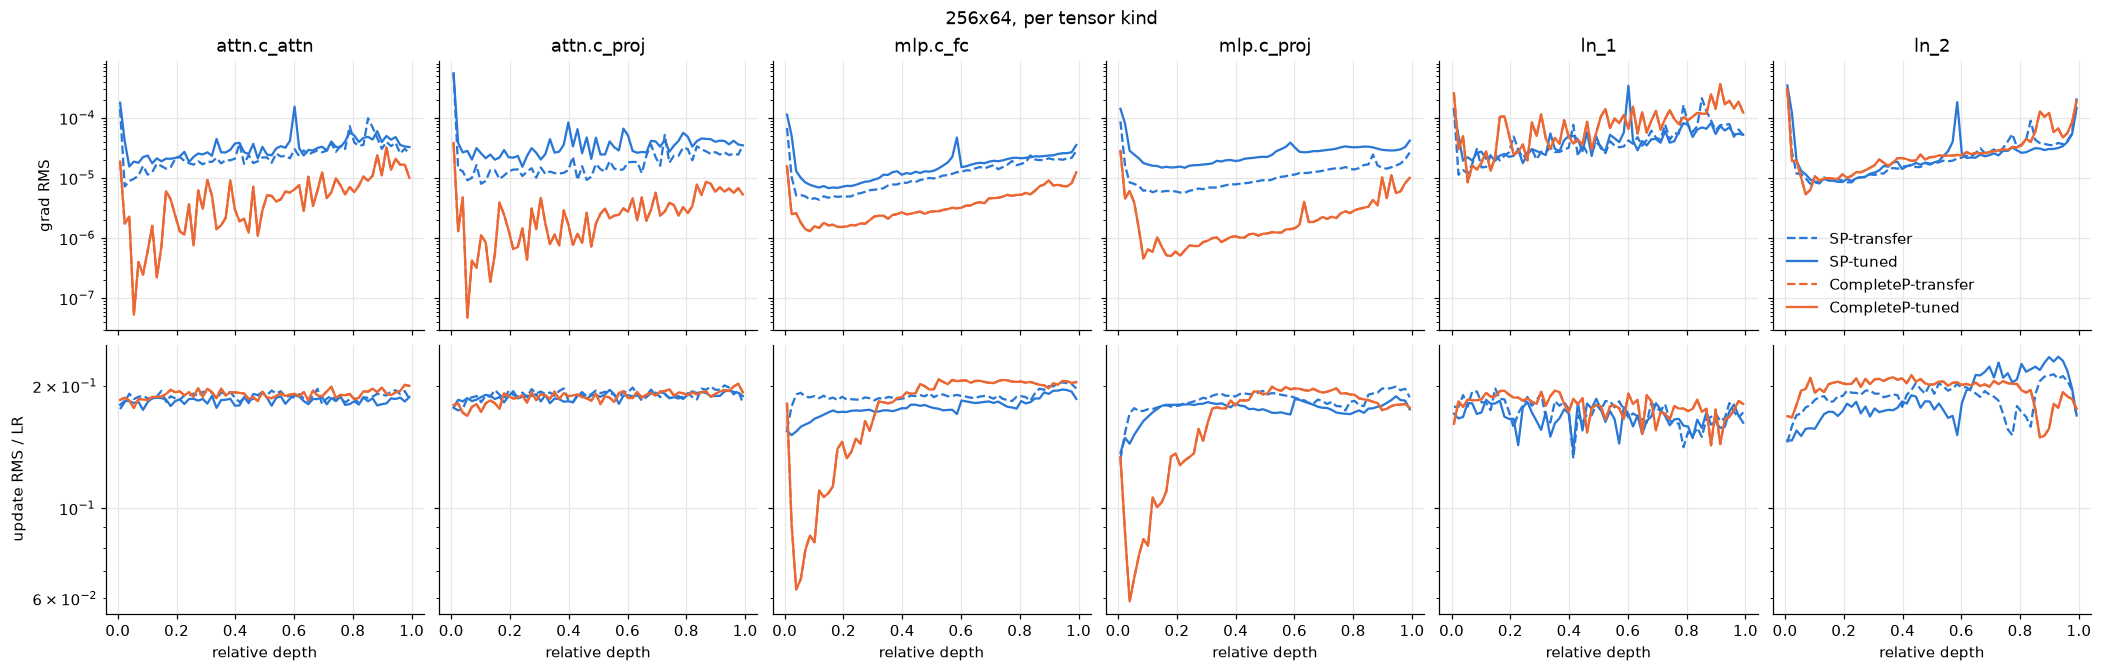

In [30]:
KIND_SHAPE = "256x64"
kinds_all = MATRIX + NORMS
fig, axes = plt.subplots(2, len(kinds_all), figsize=(19, 6), sharex=True, sharey="row", constrained_layout=True)
for j, k in enumerate(kinds_all):
    for c in COND:
        r = run_of(c, KIND_SHAPE)
        if r is None or diag(r["name"]) is None :
            continue
        for i, m in enumerate(["grad_rms", "update_over_lr"]):
            x, y = profile(r["name"], m, [k])
            axes[i, j].plot(x, y, color=STYLE[c]["color"], linestyle=STYLE[c]["linestyle"], linewidth=1.5, label=COND[c])
    axes[0, j].set_title(k)
    axes[1, j].set_xlabel("relative depth")
axes[0, 0].set_yscale("log")
axes[1, 0].set_yscale("log")
axes[0, 0].set_ylabel("grad RMS")
axes[1, 0].set_ylabel("update RMS / LR")
axes[0, -1].legend()
fig.suptitle(f"{KIND_SHAPE}, per tensor kind")
plt.show()

### Embedding and final LayerNorm

`wte` is the shared embedding / unembedding matrix (tied), `ln_f` the final LayerNorm gain, over training.

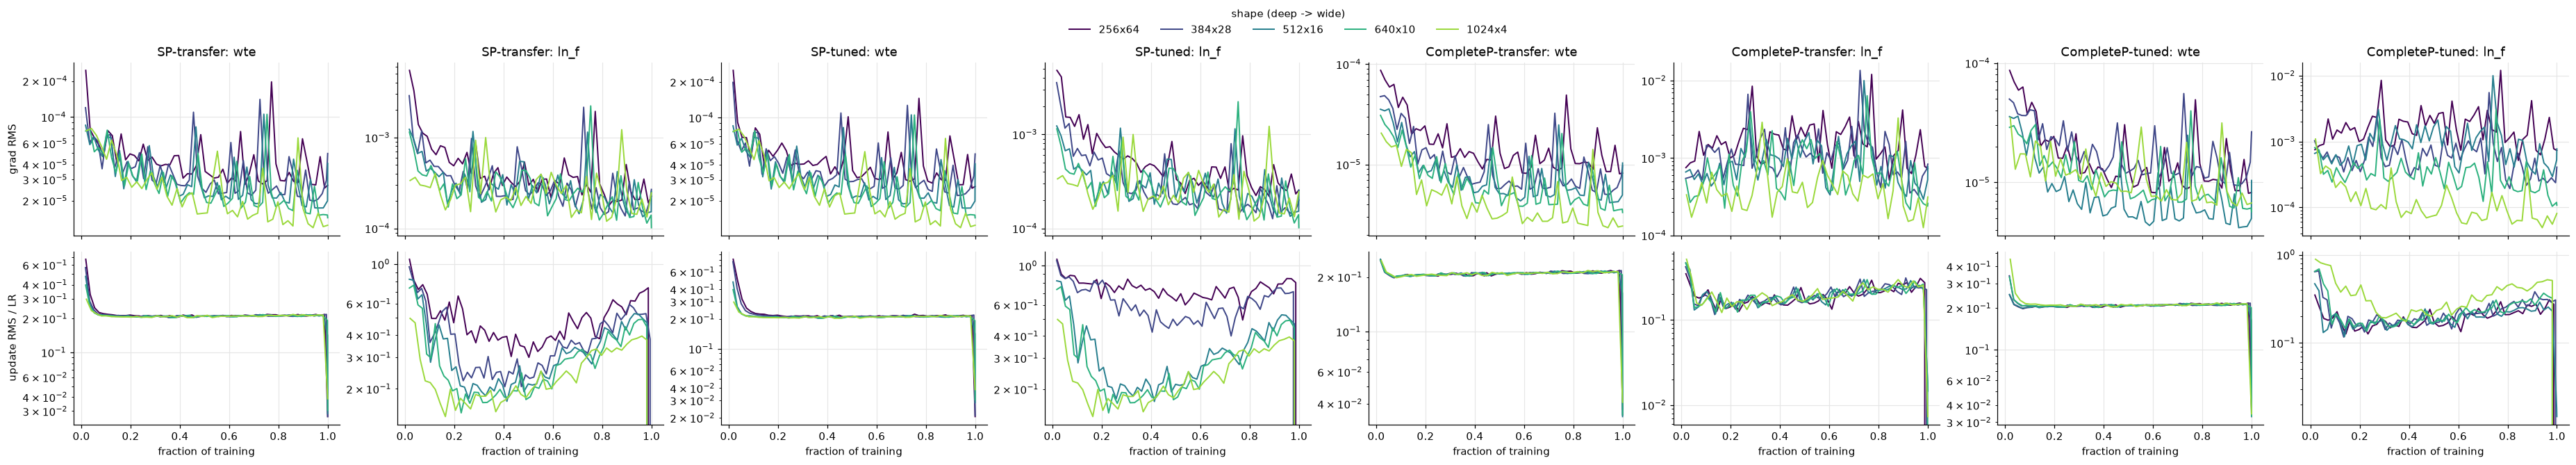

In [31]:
fig, axes = plt.subplots(2, 2 * len(conds), figsize=(4.2 * 2 * len(conds), 6), sharex=True, squeeze=False,
                         constrained_layout=True)
for j, c in enumerate(conds):
    for s in SHAPES:
        r = run_of(c, s)
        if r is None or diag(r["name"]) is None:
            continue
        df = diag(r["name"])
        for k_i, k in enumerate(["wte", "ln_f"]):
            g = df[(df["kind"] == k) & (df["iter"] > 0)]
            for i, m in enumerate(["grad_rms", "update_over_lr"]):
                axes[i, 2 * j + k_i].plot(g["frac"], g[m], color=SHAPE_COLORS[s], linewidth=1.3, label=s)
    for k_i, k in enumerate(["wte", "ln_f"]):
        axes[0, 2 * j + k_i].set_title(f"{COND[c]}: {k}")
        axes[-1, 2 * j + k_i].set_xlabel("fraction of training")
for ax in axes.flat:
    ax.set_yscale("log")
axes[0, 0].set_ylabel("grad RMS")
axes[1, 0].set_ylabel("update RMS / LR")
shape_legend(fig, axes)
plt.show()

### $\epsilon$ and starvation

Adam's update degrades only where $\sqrt{\hat v} \lesssim \epsilon$. Left: the smallest per-layer gradient RMS
of each run over training (any kind, any layer), with $\epsilon = 10^{-16}$ (ours; CompleteP scales it further down
per group) and $10^{-8}$ (PyTorch default, the planned ablation) for reference.
RMS is not elementwise: the table has the elementwise fractions (`frac_g_below_eps`: entries with $|g| < \epsilon$;
`frac_sqrtv_below_eps`: entries where Adam's denominator is below $\epsilon$, the real criterion).
Nonzero fractions in `wte` can be embedding entries that got no gradient that step.

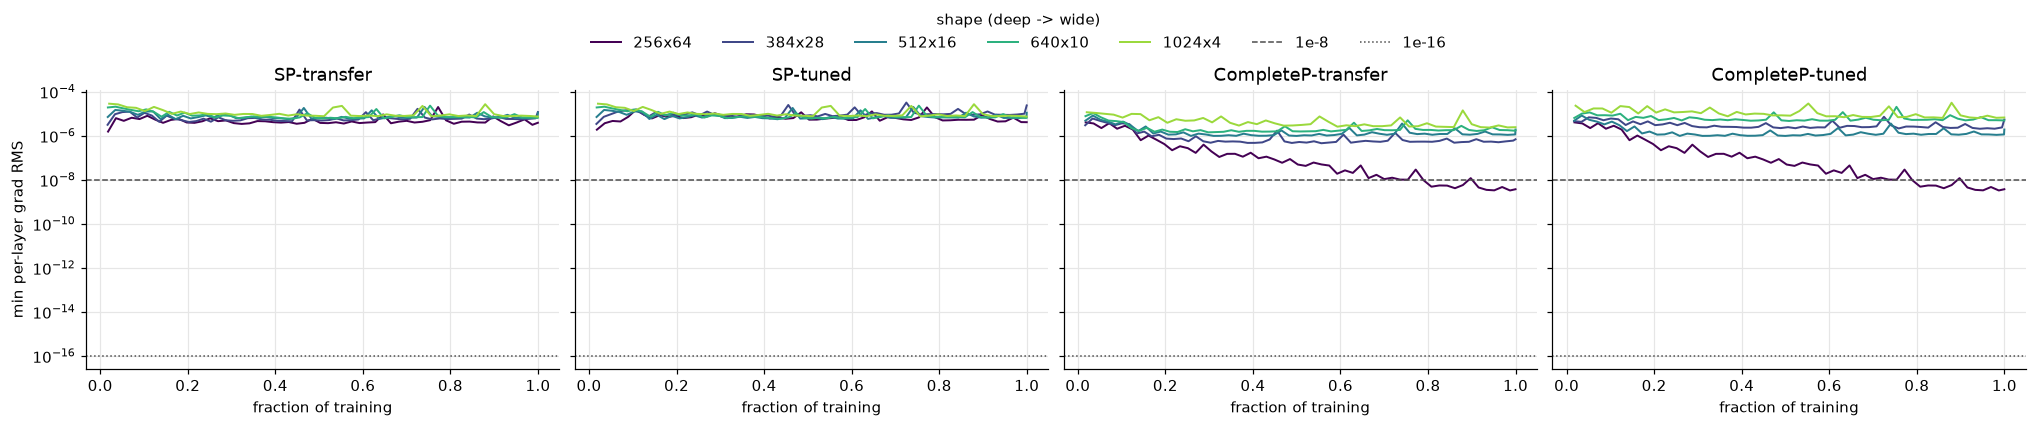

,name,eps (min..max over groups),min grad RMS,at,max frac |g|<eps,where (g),max frac sqrt(v)<eps,where (v)
0,completep-1024x4,1.2e-17..2.5e-17,2.350000e-06,wte,0.037800,"mlp.c_proj, layer 1, step 2200",0.025290,"mlp.c_proj, layer 1, step 3300"
1,completep-256x64,3.1e-18..1e-16,3.276000e-09,"attn.c_attn, layer 3",0.927700,"mlp.c_proj, layer 2, step 3700",0.921200,"mlp.c_proj, layer 2, step 4000"
2,completep-384x28,4.8e-18..6.7e-17,4.569000e-07,"mlp.c_proj, layer 2",0.783900,"mlp.c_proj, layer 1, step 3600",0.776300,"mlp.c_proj, layer 1, step 4000"
3,completep-512x16,6.2e-18..5e-17,9.810000e-07,"mlp.c_proj, layer 1",0.558200,"mlp.c_proj, layer 1, step 2600",0.499400,"mlp.c_proj, layer 1, step 3500"
4,completep-640x10,8e-18..4e-17,1.426000e-06,"mlp.c_proj, layer 1",0.339200,"mlp.c_proj, layer 1, step 2600",0.275900,"mlp.c_proj, layer 1, step 3800"
5,completep-tuned-1024x4,1.2e-17..2.5e-17,6.354000e-06,wte,0.000283,"attn.c_proj, layer 2, step 4500",0.000000,"wte, step 100"
6,completep-tuned-384x28,4.8e-18..6.7e-17,2.073000e-06,"attn.c_proj, layer 8",0.227900,"mlp.c_proj, layer 2, step 2600",0.178000,"mlp.c_proj, layer 2, step 3800"
7,completep-tuned-640x10,8e-18..4e-17,4.685000e-06,"mlp.c_proj, layer 2",0.000337,"attn.c_proj, layer 7, step 5200",0.000000,"wte, step 100"
8,sp-512x16,1e-16..1e-16,5.622000e-06,"mlp.c_proj, layer 1",0.001730,"mlp.c_proj, layer 1, step 3100",0.000488,"mlp.c_proj, layer 1, step 2900"
9,sp-transfer-1024x4,1e-16..1e-16,7.423000e-06,"mlp.c_proj, layer 1",0.000303,"attn.c_proj, layer 1, step 4889",0.000000,"wte, step 100"


In [32]:
fig, axes = plt.subplots(1, len(conds), figsize=(4.6 * len(conds), 3.8), sharey=True, squeeze=False,
                         constrained_layout=True)
for ax, c in zip(axes[0], conds):
    for s in SHAPES:
        r = run_of(c, s)
        if r is None or diag(r["name"]) is None:
            continue
        df = diag(r["name"])
        g = df[df["iter"] > 0].groupby("frac")["grad_rms"].min()
        ax.plot(g.index, g.values, color=SHAPE_COLORS[s], linewidth=1.3, label=s)
    ax.axhline(1e-8, color="0.3", linestyle="--", linewidth=1, label="1e-8")
    ax.axhline(1e-16, color="0.3", linestyle=":", linewidth=1, label="1e-16")
    ax.set_yscale("log")
    ax.set_title(COND[c])
    ax.set_xlabel("fraction of training")
axes[0, 0].set_ylabel("min per-layer grad RMS")
shape_legend(fig, axes)
plt.show()

rows = []
for name in FINAL.index:
    df = diag(name)
    if df is None:
        continue
    d_ = df[df["iter"] > 0]
    worst = lambda col: (lambda w: f"{where(w)}, step {int(w['iter'])}")(d_.loc[d_[col].idxmax()])
    smallest = d_.loc[d_["grad_rms"].idxmin()]
    rows.append({"name": name, "eps (min..max over groups)": f"{df['eps'].min():.2g}..{df['eps'].max():.2g}",
                 "min grad RMS": smallest["grad_rms"],
                 "at": where(smallest),
                 "max frac |g|<eps": d_["frac_g_below_eps"].max(), "where (g)": worst("frac_g_below_eps"),
                 "max frac sqrt(v)<eps": d_["frac_sqrtv_below_eps"].max(), "where (v)": worst("frac_sqrtv_below_eps")})
pd.DataFrame(rows)

## 7. Appendix: coordinate check

From `results/coord_check/plots/` (written by `analysis/plot_coord_check.py`). How to read it:
under pre-LN the discriminating panel is the residual stream ("last block"), which should be flat in depth and width
for CompleteP only.

depth.png


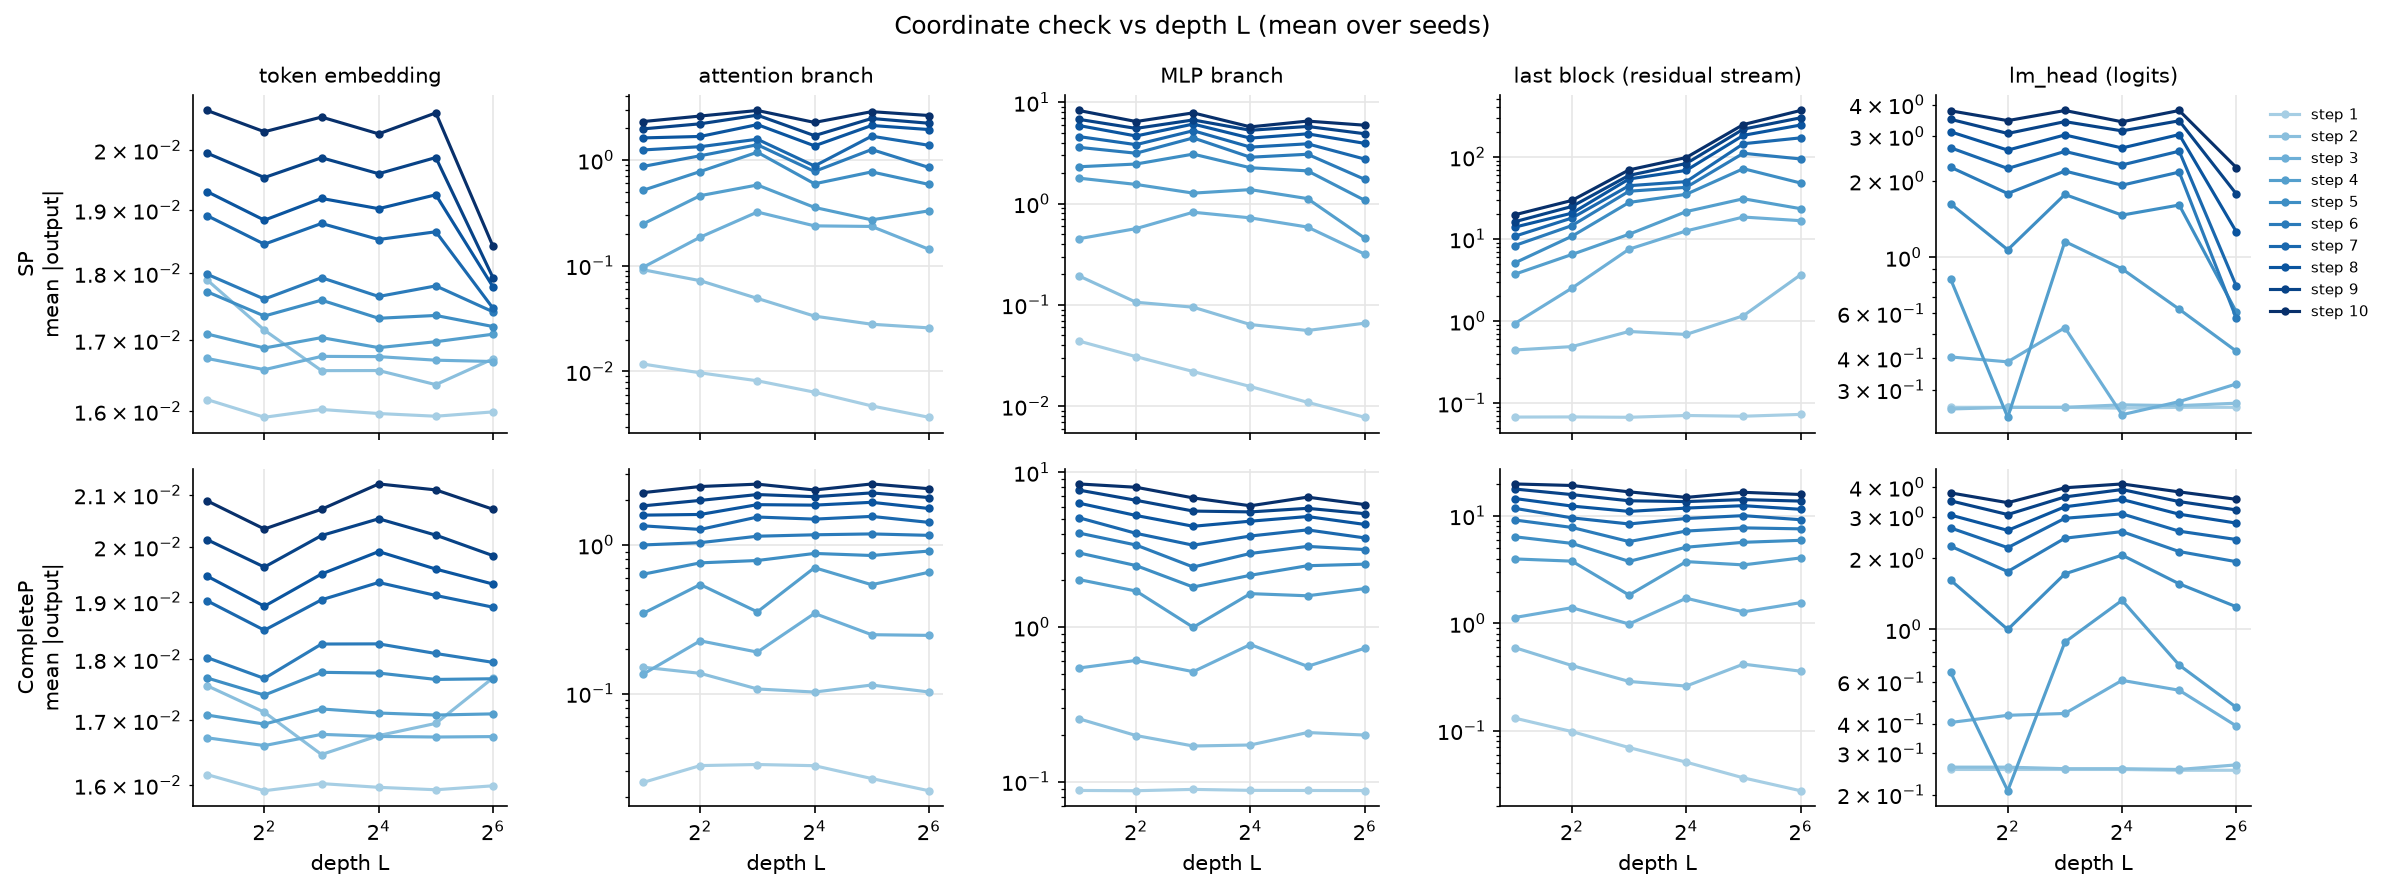

width.png


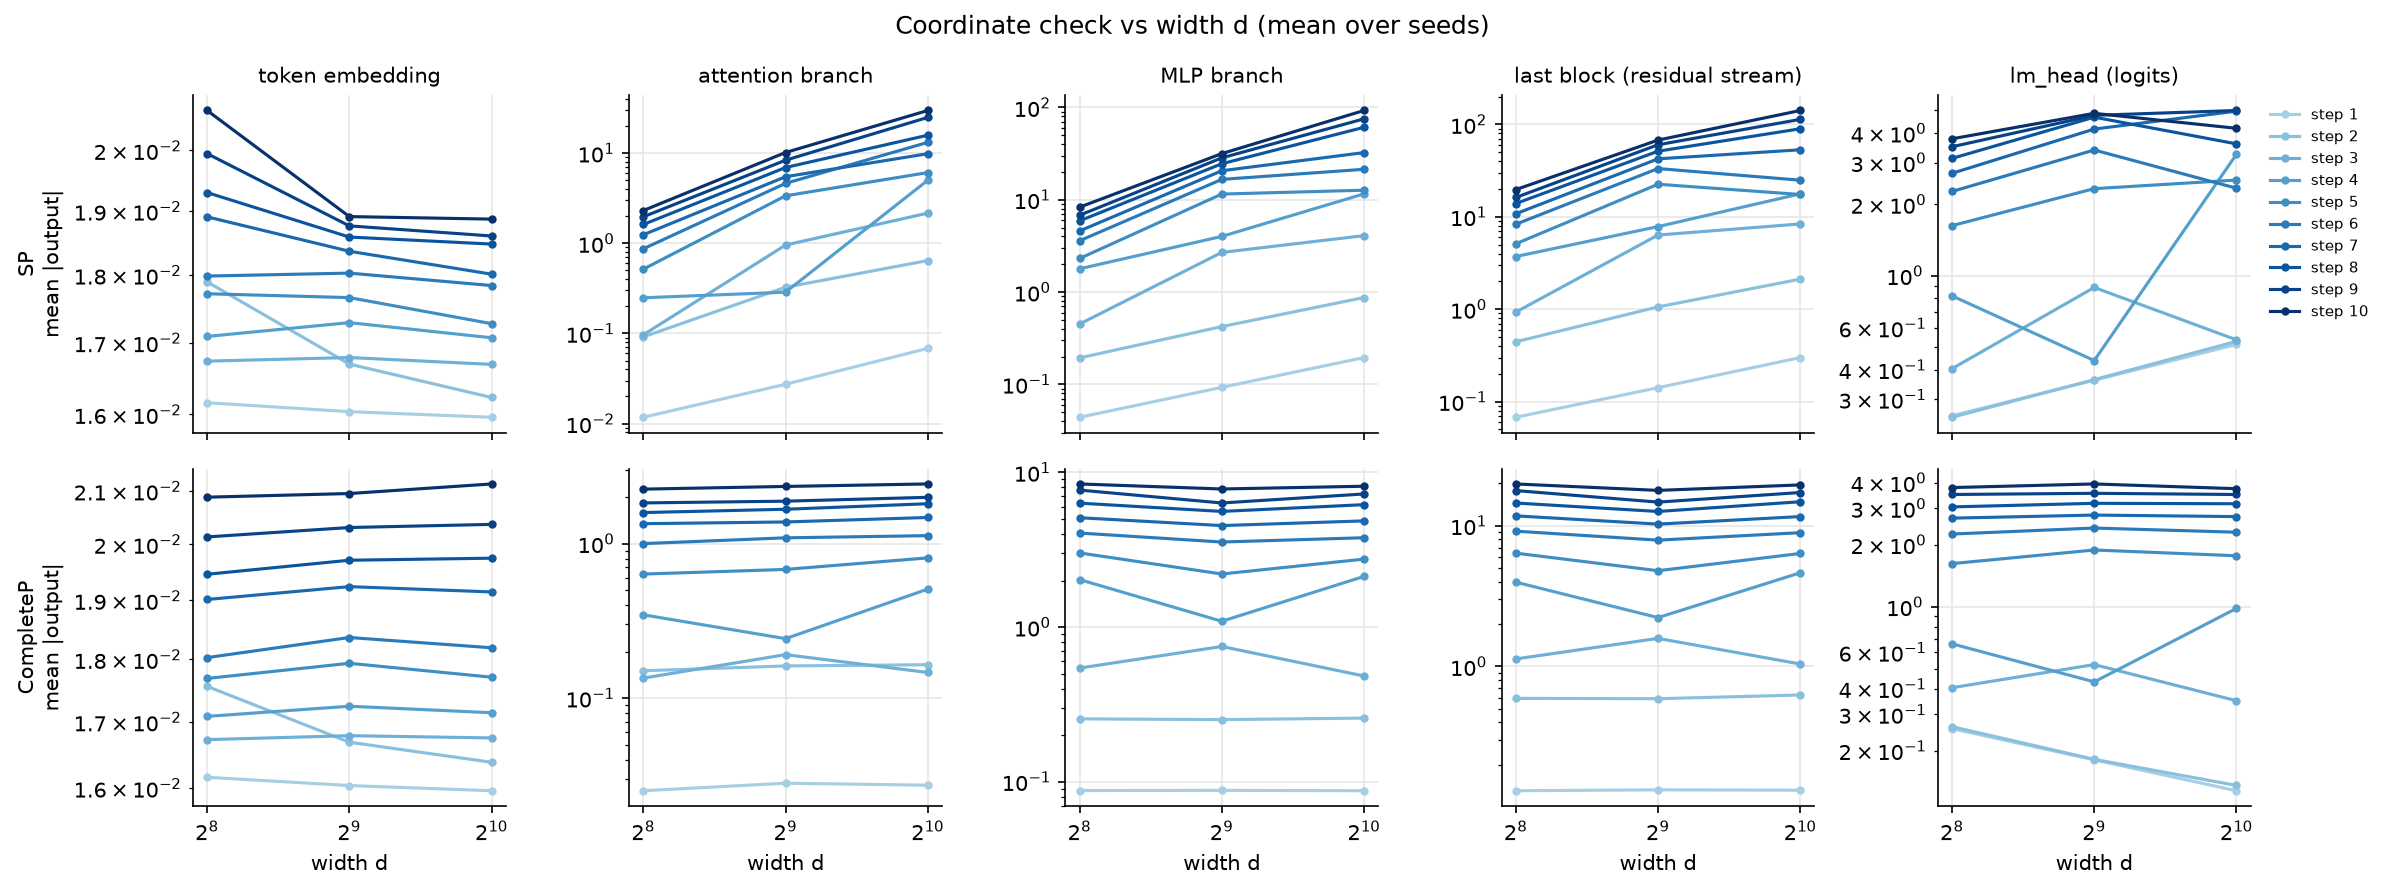

In [33]:
from IPython.display import Image, display

for p in sorted((RESULTS / "coord_check" / "plots").glob("*.png")):
    print(p.name)
    display(Image(filename=p))